# Khai phá dữ liệu người bán Olist - Pattern Mining → Classification (Nhóm 2)


**Bài toán.** Mỗi *người bán (seller)* là một "giao dịch" (transaction). Từ các đặc trưng vận hành (số đơn, doanh số, giá TB, thời gian giao, tỷ lệ giao trễ, số ngành, tỷ lệ phí vận chuyển, tỷ lệ trả thẻ, tỷ lệ bán xuyên vùng, vùng của người bán) ta:
1. **Khai phá luật kết hợp có lớp (Class Association Rules, CAR)** để tìm các tổ hợp đặc trưng đi kèm với seller *Good* (review TB >= 4,0) hoặc *NeedsSupport* (review TB < 4,0);
2. **Dùng luật như đặc trưng mới** cho bài toán phân loại và kiểm tra bằng thực nghiệm (cross-validation + kiểm định thống kê) xem luật có thật sự giúp mô hình hay không.

Mỗi cell có một khung mô tả cho từng bước: **Mục đích → Input → Cách làm → Output → Kết quả / lưu ý**. 


| Phần trong notebook | Tương ứng bản Word của nhóm |
|---|---|
| 0–2: cài đặt, nạp CSV, thư viện hàm | — (hạ tầng) |
| 5.1 Chuẩn bị dữ liệu, 5.1.1 chất lượng + nhãn sát ngưỡng, 5.1.2 tương quan, 5.1.3 rời rạc hoá, 5.1.4 kiểm định đơn biến | Bảng 5.1, 5.3, **5.4**, Hình 5.1 |
| 5.2 minsup / minconf | Hình 5.2, Bảng 5.5 |
| 5.3 So sánh 4 thuật toán; 5.4 các luật được chọn, độ phủ | Bảng 5.6–5.10, Hình 5.3 |
| 6.1 Bảng feature; 6.2 mô hình + CV 15 fold | Bảng 6.1–6.5 |
| 6.3.2 Kết quả CV, boxplot; 6.3.3 Friedman, Wilcoxon/Holm, Nadeau–Bengio, McNemar; 6.3.4 cờ nhị phân vs RuleScore | Bảng 6.6–6.11, Hình 6.1–6.2 |
| 6.4 Thí nghiệm bổ sung (k luật, cách chọn, `cancel_rate`); 6.5 minsup theo lớp | Mục mở rộng / 6.4 |
| Kết luận | Chương 7 |

**Nguyên tắc xuyên suốt:**
- **Chống rò rỉ nhãn:** `avg_review` là nguồn gốc của nhãn nên **không bao giờ** được đưa vào làm feature.
- **Chống rò rỉ khi đánh giá:** rời rạc hoá, lọc item hiếm, khai phá, chọn luật và RuleScore được *fit lại bên trong từng fold*. **Ngoại lệ:** sàng lọc tương quan (loại `avg_freight_ratio`) chỉ chạy **một lần** trên tập train 70% của phép chia giữ lại rồi cố định cho mọi fold — một rò rỉ nhẹ, đã nêu trong bản Word.
- **Báo cáo trung thực:** kết quả yếu hoặc không có ý nghĩa thống kê được ghi đúng như vậy.

**Yêu cầu môi trường:** Python ≥ 3.9 và `pip install pandas numpy scipy scikit-learn mlxtend statsmodels matplotlib seaborn`. Đặt `adm_olist_selling_cube_mining.csv` vào thư mục `Downloads`.


### 0.1 Quy trình dữ liệu từ BigQuery đến notebook

- **`v_olap`**: giao dịch hợp lệ (có trong `olist_preprocessed_all`) của đơn **Completed** => Input cho toàn bộ số liệu của pattern mining của nhóm
-  **`v_olap_all`**: mọi trạng thái đơn (dùng để tính `cancel_rate`).
- **`seller_cube`** (mỗi seller một dòng) gồm 15–16 cột: `seller_id, seller_region, seller_state, n_orders, total_sales, avg_price, avg_review, avg_delivery_days, late_rate, n_categories, avg_freight_ratio, credit_card_share, cross_region_share, n_orders_all, cancel_rate, avg_distance_km`.
- **`seller_mining`** = `seller_cube` lọc `n_orders ≥ 10` và thêm cột `label` (Good nếu `avg_review ≥ 4,0`).
- Thuộc tính cấp **đơn** (review, ngày giao, trễ hẹn, thanh toán, vùng khách) được lấy **một giá trị cho mỗi (seller, đơn)** trước khi trung bình theo seller, vì `v_olap` có một dòng cho mỗi *dòng hàng*; không làm vậy thì đơn nhiều dòng hàng bị đếm lặp.

In [2]:
# Bước 0: cài các thư viện cần thiết (chỉ cần chạy một lần; có thể bỏ qua nếu đã cài)
%pip install -q numpy pandas matplotlib seaborn ipython scipy scikit-learn mlxtend statsmodels

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
pip install -q numpy pandas matplotlib seaborn ipython scipy scikit-learn mlxtend statsmodels

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Cài đặt môi trường, đường dẫn và hằng số

**Mục đích:** Nạp thư viện, tạo thư mục kết quả, đặt các hằng số *một lần duy nhất* để mọi cell phía sau dùng chung.

**Input** Không có.

**Cách làm.**
- `MIN_ORDERS = 10`: chỉ giữ seller có ≥ 10 đơn. Lý do: review TB của seller chỉ có 1–3 đơn rất nhiễu (một đánh giá 1 sao kéo TB xuống), dùng làm nhãn sẽ sai.
- `LABEL_THR = 4.0`: nhãn *Good* nếu `avg_review ≥ 4,0`. Ngưỡng 4,0 tương ứng "khách hài lòng" (4–5 sao).
- `SEED_SPLIT = 42` (chia train/test cho phần khai phá), `SEED_CV = 2024` (lặp CV). Cố định seed để chạy lại ra đúng cùng kết quả.
- `MINSUP`, `MINCONF`, `FEATURE_MINSUP`: ngưỡng khai phá luật; được giải thích ở mục 6.

**Output:** Thư mục `out/`, `figs/`; các biến toàn cục.


In [10]:
import os, sys, time, pickle, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings('ignore')
%matplotlib inline
pd.set_option('display.width', 250)
pd.set_option('display.max_colwidth', 110)
pd.set_option('display.max_columns', 60)

# Windows: để in được tiếng Việt
try:
    sys.stdout.reconfigure(encoding='utf-8')
except Exception:
    pass

# Thư mục lưu kết quả (out) và hình (figs) nằm cạnh notebook
BASE = Path.cwd()
OUT = BASE / 'out'
FIG = BASE / 'figs'
OUT.mkdir(exist_ok=True)
FIG.mkdir(exist_ok=True)

MIN_ORDERS = 10      # chỉ giữ seller có >= 10 đơn (review trung bình đủ ổn định để làm nhãn)
LABEL_THR = 4.0      # Good nếu avg_review >= 4.0
SEED_SPLIT = 42      # seed chia train/test (phần khai phá + hold-out)
SEED_CV = 2024       # seed cross-validation (5 fold x 3 lần lặp = 15 fold)
print('Thư mục làm việc:', BASE)

Thư mục làm việc: c:\Users\ttranhan\Downloads


### 1.1 Nạp bảng seller từ file CSV trong thư mục Downloads

**Mục đích:** Lấy bảng đặc trưng mức seller (mỗi dòng = 1 seller) mà toàn bộ phần khai phá dùng. 
=> Cần lưu file **chỉ đọc một file CSV duy nhất**: `Downloads/adm_olist_selling_cube_mining.csv`

**Đường dẫn:** `Path.home() / 'Downloads' / 'adm_olist_selling_cube_mining.csv'` — tự trỏ tới thư mục Downloads của người dùng hiện tại trên Windows, macOS và Linux. Nếu file nằm chỗ khác, chỉ cần sửa biến `INPUT_CSV`.

**Cột bắt buộc:** `seller_id, seller_region, n_orders, total_sales, avg_price, avg_review, avg_delivery_days, late_rate, n_categories, avg_freight_ratio, credit_card_share, cross_region_share`. Cột tuỳ chọn: `label`, `cancel_rate`, `avg_distance_km`, `n_orders_all`, `seller_state`.

**Output:** `SELLER_DF` (bảng seller thô); in ra đường dẫn đã đọc, số seller và danh sách cột.

In [5]:
# Đường dẫn file CSV (sửa dòng này nếu file nằm chỗ khác)
INPUT_CSV = Path.home() / 'Downloads' / 'adm_olist_selling_cube_mining.csv'

REQUIRED_COLS = ['seller_id', 'seller_region', 'n_orders', 'total_sales', 'avg_price', 'avg_review',
                 'avg_delivery_days', 'late_rate', 'n_categories', 'avg_freight_ratio',
                 'credit_card_share', 'cross_region_share']

if not INPUT_CSV.exists():
    raise FileNotFoundError(f'Không thấy file: {INPUT_CSV}. Hãy đặt file vào thư mục Downloads hoặc sửa INPUT_CSV.')

# float_precision='round_trip' giữ nguyên đủ chữ số (xem mục 5.1.1b về giá trị 3.9999999999999996)
SELLER_DF = pd.read_csv(INPUT_CSV, float_precision='round_trip')
print('Nguồn: CSV ->', INPUT_CSV)

missing_cols = [c for c in REQUIRED_COLS if c not in SELLER_DF.columns]
assert len(missing_cols) == 0, f'Bảng seller thiếu cột: {missing_cols}'
print(f'{len(SELLER_DF):,} seller | các cột: {list(SELLER_DF.columns)}')

Nguồn: CSV -> C:\Users\ttranhan\Downloads\adm_olist_selling_cube_mining.csv
1,237 seller | các cột: ['seller_id', 'seller_region', 'seller_state', 'n_orders', 'total_sales', 'avg_price', 'avg_review', 'avg_delivery_days', 'late_rate', 'n_categories', 'avg_freight_ratio', 'credit_card_share', 'cross_region_share', 'n_orders_all', 'cancel_rate', 'avg_distance_km', 'label']


## 2. Thư viện dùng chung (thay cho `lib_rules.py`)

Sơ đồ tổng thể:

```
bảng seller ─► fit_cut_points / to_items (qcut 3 mức) ─► to_onehot (item "attr=value" + item lớp)
            ─► mine_apriori / mine_fpgrowth / mine_eclat ─► tập phổ biến ─► closed_filter (CHARM-closed)
            ─► gen_cars (luật  {antecedent} ⇒ lớp, tính sup/conf/lift/leverage/χ²/wχ²)
            ─► select_rules (chọn 3 luật, cân bằng lớp, chống trùng độ phủ)
            ─► rules_to_features / rule_score_features (luật → cột đặc trưng cho mô hình)
```

### 2.1 Rời rạc hoá (`fit_cut_points`, `to_items`) và biến đổi sang ma trận item (`to_onehot`)

**Mục đích:** Thuật toán luật kết hợp làm việc với *item rời rạc*, nên mỗi feature số được chia thành 3 mức **Low / Medium / High** theo tam phân vị (qcut); feature phân loại (vùng) giữ nguyên giá trị.

**Cách làm:**
- `fit_cut_points(train, cột)` tính **các mốc cắt chỉ trên tập train** (hai đầu mốc đặt ±∞ để dữ liệu test ngoài khoảng vẫn rơi vào Low/High). `to_items(df, mốc, cột_phân_loại)` áp mốc đó cho bất kỳ tập nào → **không rò rỉ** thông tin từ test.
- Nếu một feature có quá nhiều giá trị trùng khiến không đủ 3 mốc, `duplicates='drop'` tự giảm số mức.
- Mỗi ô được ghi thành chuỗi `"tên_feature=mức"` (ví dụ `late_rate=High`) -> chính là một **item**.
- `to_onehot` biến bảng item thành ma trận bool (cột = item, hàng = seller). Nếu truyền nhãn `y`, nó thêm hai *item lớp* `Performance=Good` và `Performance=NeedsSupport` để luật có dạng `{item…} ⇒ lớp`.

**Output:** Hàm `fit_cut_points`, `to_items`, `to_onehot`, hằng `CLASS_ITEMS`.

**Lưu ý:** Chia theo phân vị khiến mỗi mức chứa ≈ 1/3 seller, nên support của một item đơn lẻ ≈ 33% — đó là lý do ngưỡng `minsup = 5%` (mục 5.2) khá thoải mái cho item đơn nhưng chặt cho tổ hợp 3–4 item.

In [11]:
from mlxtend.frequent_patterns import apriori, fpgrowth

CLASS_ITEMS = ['Performance=Good', 'Performance=NeedsSupport']
LEVELS = ['Low', 'Medium', 'High']


def fit_cut_points(train, num_cols, n_bins=3):
    """Tính mốc cắt tam phân vị cho từng cột số, CHỈ trên tập train."""
    cuts = {}
    for col in num_cols:
        _, edges = pd.qcut(train[col], q=n_bins, retbins=True, duplicates='drop')
        edges[0] = -np.inf      # hai đầu đặt ±∞ để dữ liệu ngoài khoảng vẫn rơi vào Low/High
        edges[-1] = np.inf
        cuts[col] = edges
    return cuts


def to_items(df, cuts, cat_cols):
    """Đổi mỗi ô thành item dạng 'tên_cột=mức' bằng mốc cắt đã học."""
    items = pd.DataFrame(index=df.index)
    for col, edges in cuts.items():
        labels = LEVELS[:len(edges) - 1]
        levels = pd.cut(df[col], bins=edges, labels=labels).astype(str)
        items[col] = col + '=' + levels
    for col in cat_cols:
        items[col] = col + '=' + df[col].astype(str)
    return items


def to_onehot(items_df, label=None):
    """Bảng item -> ma trận bool (cột = item, hàng = seller).
    Nếu có nhãn y (1 = Good, 0 = NeedsSupport) thì thêm 2 item lớp."""
    columns = {}
    for col in items_df.columns:
        for value in items_df[col].dropna().unique():
            columns[value] = (items_df[col] == value).values
    if label is not None:
        columns['Performance=Good'] = (label.values == 1)
        columns['Performance=NeedsSupport'] = (label.values == 0)
    return pd.DataFrame(columns, index=items_df.index)

### 2.2 Bốn thuật toán khai phá tập phổ biến

**Mục đích:** Tìm mọi tập item có support ≥ `minsup`. Dùng 3 thuật toán kinh điển + 1 thuật toán nâng cao để *đối chiếu*:

| Thuật toán | Ý tưởng | Cài đặt |
|---|---|---|
| **Apriori** | Sinh ứng viên theo từng mức (k-itemset → (k+1)-itemset), cắt tỉa nhờ tính chất "tập con của tập phổ biến cũng phổ biến" | `mlxtend.apriori` |
| **FP-Growth** | Nén dữ liệu thành cây FP-tree rồi khai phá đệ quy, không sinh ứng viên | `mlxtend.fpgrowth` |
| **ECLAT** | Biểu diễn **dọc**: mỗi item có *tidset* (tập seller chứa nó); support = kích thước giao các tidset; duyệt DFS | **tự cài đặt** bằng tập chỉ số seller (`set`) và phép giao tập |
| **CHARM-closed** *(advanced)* | Chỉ giữ **tập đóng** (không có tập cha nào cùng support) → loại luật dư thừa | `closed_filter` (lọc hậu kỳ, cho kết quả tương đương CHARM ở quy mô này) |

**Output:** Hàm `mine_apriori`, `mine_fpgrowth`, `mine_eclat`, `closed_filter`; từ điển `ALGOS`.

**Lưu ý:** `max_len = 4` giới hạn độ dài tập (vế trái tối đa 3 item + 1 item lớp) để luật còn *đọc được* và tránh bùng nổ tổ hợp. Cả 3 thuật toán đầu **phải cho đúng cùng tập kết quả** (chỉ khác thời gian) — mục 5.3 kiểm tra điều này như một phép thử tính đúng đắn của cài đặt ECLAT.

In [12]:
def mine_apriori(B, minsup, max_len=4):
    return apriori(B, min_support=minsup, use_colnames=True, max_len=max_len)


def mine_fpgrowth(B, minsup, max_len=4):
    return fpgrowth(B, min_support=minsup, use_colnames=True, max_len=max_len)


def mine_eclat(B, minsup, max_len=4):
    """ECLAT: mỗi item có 'tidset' = tập chỉ số seller chứa item đó.
    Support của một tập item = số seller trong giao các tidset / tổng số seller. Duyệt theo chiều sâu (DFS)."""
    n = len(B)
    min_count = int(np.ceil(minsup * n))

    tidsets = {}
    for col in B.columns:
        tidsets[col] = set(np.where(B[col].values)[0])

    # chỉ giữ item đủ phổ biến, sắp theo support tăng dần
    frequent_items = [col for col in B.columns if len(tidsets[col]) >= min_count]

    def tidset_size(col):
        return len(tidsets[col])

    frequent_items = sorted(frequent_items, key=tidset_size)
    candidates = [(col, tidsets[col]) for col in frequent_items]

    results = []

    def search(prefix, candidates):
        for i in range(len(candidates)):
            item, tids = candidates[i]
            itemset = prefix + [item]
            results.append((frozenset(itemset), len(tids) / n))
            if len(itemset) < max_len:
                next_candidates = []
                for j in range(i + 1, len(candidates)):
                    item2, tids2 = candidates[j]
                    common = tids & tids2
                    if len(common) >= min_count:
                        next_candidates.append((item2, common))
                if len(next_candidates) > 0:
                    search(itemset, next_candidates)

    search([], candidates)
    return pd.DataFrame({'support': [r[1] for r in results], 'itemsets': [r[0] for r in results]})


def closed_filter(fi):
    """Giữ tập ĐÓNG: loại itemset nếu có tập cha (chứa nó) cùng support."""
    fi = fi.copy()
    supports = fi.support.round(10).tolist()
    itemsets = fi.itemsets.tolist()

    # gom các itemset có cùng support lại với nhau
    groups = {}
    for i in range(len(fi)):
        groups.setdefault(supports[i], []).append(i)

    keep = [True] * len(fi)
    for ids in groups.values():
        for a in ids:
            for b in ids:
                if a != b and itemsets[a] < itemsets[b]:    # itemsets[a] là tập con thật sự của itemsets[b]
                    keep[a] = False
                    break
    return fi[keep]


ALGOS = {'Apriori': mine_apriori, 'FP-Growth': mine_fpgrowth, 'ECLAT': mine_eclat}

### 2.3 Sinh luật kết hợp có lớp — CAR (`chi2_stats`, `gen_cars`)

**Mục đích:** Từ tập phổ biến có chứa *đúng 1 item lớp*, sinh luật `{vế trái} ⇒ lớp` và tính các chỉ số chất lượng.

**Các chỉ số (N = số seller train):**
- **support** = P(điều kiện ∧ lớp): luật phủ bao nhiêu seller.
- **confidence** = P(lớp | điều kiện): trong số seller khớp vế trái, bao nhiêu % thuộc lớp.
- **lift** = confidence / P(lớp): > 1 nghĩa là vế trái (điều kiện) làm tăng khả năng thuộc lớp so với ngẫu nhiên => *Rất quan trọng với dữ liệu lệch lớp*: lớp Good chiếm ~76% nên confidence 0,76 chưa nói lên điều gì (lift = 1).
- **leverage** = support − P(vế trái)·P(lớp): chênh lệch tuyệt đối so với độc lập.
- **χ² (2×2)** và **weighted χ² (wχ² của CMAR)** = χ²·χ²/max-χ²: đo ý nghĩa thống kê có chuẩn hoá theo giá trị tối đa có thể.

**Ngưỡng confidence theo lớp (`minconf` dạng dict).** Lớp thiểu số (*NeedsSupport*, ~24%) cần minconf thấp hơn (0,40) vì confidence 0,40 đã tương ứng lift ≈ 1,7; trong khi lớp Good cần 0,60.

**Cách làm:** Với mỗi tập phổ biến `s` có đúng một item lớp: vế trái = `s` bỏ item lớp; support của vế trái lấy từ `full_fi` (cần khi `fi` chỉ gồm tập *đóng*, vì support vế trái có thể nằm ngoài tập đóng); loại luật có confidence dưới ngưỡng.

**Output:** DataFrame các CAR với cột `antecedent, cls, support, confidence, lift, leverage, chi2, wchi2, length, n_ante`.

In [14]:
def chi2_stats(sup_p, sup_c, sup_pc, N):
    """Tính χ² (bảng 2x2) và χ² lớn nhất có thể (dùng cho weighted χ² kiểu CMAR).
    sup_p: số seller khớp vế trái | sup_c: số seller thuộc lớp | sup_pc: số seller thoả cả hai | N: tổng seller."""
    a = sup_pc
    b = sup_p - a
    c = sup_c - a
    d = N - sup_p - sup_c + a

    # (số quan sát, tổng hàng, tổng cột) của 4 ô trong bảng 2x2
    cells = [(a, sup_p, sup_c), (b, sup_p, N - sup_c), (c, N - sup_p, sup_c), (d, N - sup_p, N - sup_c)]
    chi = 0
    for observed, row_total, col_total in cells:
        expected = row_total * col_total / N
        chi += (observed - expected) ** 2 / max(expected, 1e-9)

    e = 1 / (sup_p * sup_c) + 1 / (sup_p * (N - sup_c)) + 1 / ((N - sup_p) * sup_c) + 1 / ((N - sup_p) * (N - sup_c))
    chi_max = (min(sup_p, sup_c) - sup_p * sup_c / N) ** 2 * N * e
    return chi, chi_max


def gen_cars(fi, N, minconf=0.5, full_fi=None):
    """Từ tập phổ biến sinh luật có dạng {vế trái} => lớp.
    full_fi: bảng tập phổ biến đầy đủ để tra support của vế trái (cần khi fi là tập đóng)."""
    ref = full_fi if full_fi is not None else fi
    support_of = {}
    for itemset, sup in zip(ref.itemsets, ref.support):
        support_of[itemset] = sup

    rows = []
    for itemset, sup in zip(fi.itemsets, fi.support):
        class_in_set = [item for item in itemset if item in CLASS_ITEMS]
        if len(class_in_set) != 1 or len(itemset) < 2:
            continue                                   # luật phải có đúng 1 item lớp và >= 1 item vế trái
        class_item = class_in_set[0]
        class_name = class_item.split('=')[1]
        antecedent = frozenset(itemset - {class_item})
        if antecedent not in support_of:
            continue

        n_ante = support_of[antecedent] * N            # số seller khớp vế trái
        n_class = support_of[frozenset([class_item])] * N
        n_both = sup * N
        confidence = n_both / n_ante

        if isinstance(minconf, dict):
            threshold = minconf[class_name]
        else:
            threshold = minconf
        if confidence < threshold:
            continue

        chi, chi_max = chi2_stats(n_ante, n_class, n_both, N)
        if chi_max > 0:
            wchi2 = chi * chi / chi_max
        else:
            wchi2 = 0
        rows.append({'antecedent': tuple(sorted(antecedent)), 'cls': class_name, 'support': sup,
                     'confidence': confidence, 'lift': confidence / (n_class / N),
                     'leverage': sup - (n_class / N) * (n_ante / N),
                     'chi2': chi, 'wchi2': wchi2, 'length': len(antecedent), 'n_ante': int(n_ante)})
    return pd.DataFrame(rows)

### 2.4 Chọn luật và biến luật thành đặc trưng (`select_rules`, `rules_to_features`, `rule_score_features`)

**Mục đích.** Số CAR có thể lên hàng trăm/nghìn; ta chọn **3 luật** (2 luật *Good* + 1 luật *NeedsSupport*) đủ tốt và *không trùng nhau* để vừa đọc được vừa dùng làm đặc trưng.

**`select_rules` - 3 lớp lọc:**
1. **Lọc ý nghĩa:** chỉ giữ luật có `lift > 1` và `χ² ≥ 3,84` (p < 0,05, 1 bậc tự do). Luật lift ≤ 1 bị loại dù confidence cao.
2. **Xếp hạng theo "ranker"**, mỗi thuật toán gắn với chiến lược của paper gốc: `confidence → support` (CBA), `wχ²` (CMAR), `leverage`, ...
3. **Cân bằng lớp + database coverage:** chọn theo *quota từng lớp* (tránh cả 3 luật đều thuộc lớp đa số) và bỏ luật có **độ phủ trùng > 70%** (Jaccard) với luật đã chọn, để 3 luật bổ sung nhau.

**`rules_to_features`.** Mỗi luật → 1 cột nhị phân (seller có khớp vế trái luật hay không).

**`rule_score_features` (phương pháp đề xuất "RuleScore").** Thay vì chỉ 3 luật, dùng **tối đa 30 luật tốt nhất mỗi lớp**; mỗi seller nhận `score_Good` = tổng wχ² của các luật Good mà nó khớp, `score_NeedsSupport` tương tự, và `score_diff` = hiệu hai điểm. Ý tưởng lấy cảm hứng từ cách CMAR gộp nhiều luật khi dự đoán.

**Output:** Ba hàm và `RANKERS`, `coverage`.

In [16]:
# Mỗi cách xếp hạng = danh sách cột sắp giảm dần
RANKERS = {'confidence': ['confidence', 'support'],
           'lift': ['lift', 'support'],
           'wchi2': ['wchi2', 'support'],
           'support': ['support', 'confidence'],
           'leverage': ['leverage', 'support']}


def select_rules(cars, B, ranker='confidence', k_per_class=None, max_overlap=0.7, min_lift=1.0, min_len=1):
    """Chọn luật: lọc (lift, χ², độ dài) -> xếp hạng -> lấy k luật mỗi lớp,
    bỏ luật có độ phủ trùng > max_overlap (Jaccard) với luật đã chọn."""
    if k_per_class is None:
        k_per_class = {'Good': 2, 'NeedsSupport': 1}

    if len(cars) > 0:
        cars = cars[(cars.lift > min_lift) & (cars.chi2 >= 3.84) & (cars.length >= min_len)]

    sort_cols = RANKERS[ranker] + ['length']                       # length tăng dần (ưu tiên luật ngắn khi hoà)
    ascending = [False] * len(RANKERS[ranker]) + [True]

    picked = []
    covers = []                                                    # độ phủ (mảng bool) của các luật đã chọn
    for cls, k in k_per_class.items():
        candidates = cars[cars.cls == cls].sort_values(sort_cols, ascending=ascending)
        n_picked = 0
        for _, rule in candidates.iterrows():
            cover = B[list(rule.antecedent)].all(axis=1).values
            too_similar = False
            for other in covers:
                jaccard = (cover & other).sum() / max((cover | other).sum(), 1)
                if jaccard > max_overlap:
                    too_similar = True
                    break
            if too_similar:
                continue
            picked.append(rule)
            covers.append(cover)
            n_picked += 1
            if n_picked == k:
                break
    return pd.DataFrame(picked).reset_index(drop=True)


def rules_to_features(rules, B, prefix='R'):
    """Mỗi luật -> 1 cột 0/1 (1 nếu seller khớp vế trái)."""
    features = {}
    for i, rule in rules.iterrows():
        name = f'{prefix}{i + 1}_{rule.cls}'
        features[name] = B[list(rule.antecedent)].all(axis=1).astype(int).values
    return pd.DataFrame(features, index=B.index)


def rule_score_features(cars, B, topn=30):
    """RuleScore: với mỗi lớp, cộng wχ² của các luật (top 30) mà seller khớp; thêm score_diff = Good - NeedsSupport."""
    cars = cars[(cars.lift > 1) & (cars.chi2 >= 3.84)]
    scores = pd.DataFrame(index=B.index)
    for cls in ['Good', 'NeedsSupport']:
        top_rules = cars[cars.cls == cls].sort_values('wchi2', ascending=False).head(topn)
        total = np.zeros(len(B))
        for _, rule in top_rules.iterrows():
            matched = B[list(rule.antecedent)].all(axis=1).values
            total += rule.wchi2 * matched
        scores['score_' + cls] = total
    scores['score_diff'] = scores['score_Good'] - scores['score_NeedsSupport']
    return scores


def coverage(antecedent, B):
    """Tỷ lệ seller khớp vế trái của luật."""
    return B[list(antecedent)].all(axis=1).mean()

---
# CHƯƠNG 5 - KHAI PHÁ LUẬT KẾT HỢP

Thứ tự trình bày trong word: 5.1 chuẩn bị dữ liệu → 5.2 chọn minsup/minconf → 5.3 so sánh thuật toán → 5.4 các luật được chọn.

## 5.1 Chuẩn bị dữ liệu cho khai phá: nạp, tạo nhãn, chia train/test  *(Bảng 5.1)*

**Mục đích:** Dựng bảng seller dùng cho toàn bộ phân tích và chốt định nghĩa nhãn.

**Input:** `SELLER_DF` (mục 1.1, phần chuẩn bị).

**Cách làm:**
1. Đọc CSV, giữ seller có `n_orders ≥ MIN_ORDERS` (10), đặt `seller_id` làm chỉ số.
2. **Nhãn** `y = 1` (*Good*) nếu `avg_review ≥ 4,0`, ngược lại `y = 0` (*NeedsSupport*).
3. **Danh sách feature ban đầu (`N_BEFORE`) = 9 feature số + 1 phân loại.** `avg_review` bị **cố tình loại** vì là nguồn gốc của nhãn (nếu để lại, mô hình đạt ~100% một cách vô nghĩa — "rò rỉ nhãn"). Các cột `n_orders_all`, `cancel_rate`, `seller_state` cũng không đưa vào bộ feature chính (`cancel_rate` được thử riêng ở mục 11).
4. **Chia train/test 70/30, phân tầng theo nhãn** (`stratify=y`, seed 42) để hai tập có cùng tỷ lệ Good/NeedsSupport. **Mọi thứ học từ dữ liệu ở mục 5.1.2–5.4 chỉ dùng `tr`.**

**Output:** `s` (toàn bộ seller đủ điều kiện), `tr`, `te`, `NUM`, `CAT`, `N_BEFORE`. In ra số seller, tỷ lệ Good, danh sách feature.

**Lưu ý:** Tỷ lệ Good ≈ 76% nghĩa là dữ liệu **lệch lớp**: một mô hình ngây thơ luôn đoán "Good" đã đạt accuracy ≈ 76%. Vì vậy từ đây trở đi ta theo dõi thêm **macro-F1** và **recall của lớp NeedsSupport**, chứ không chỉ accuracy.

In [17]:
from sklearn.model_selection import train_test_split

s = SELLER_DF.copy()
s = s[s.n_orders >= MIN_ORDERS]
s = s.set_index('seller_id')

# Nhãn: 1 = Good (avg_review >= 4.0), 0 = NeedsSupport
s['y'] = (s.avg_review >= LABEL_THR).astype(int)

# Danh sách feature. avg_review KHÔNG được làm feature vì nó tạo ra nhãn (tránh rò rỉ nhãn)
NUM = ['n_orders', 'total_sales', 'avg_price', 'avg_delivery_days', 'late_rate', 'n_categories',
       'avg_freight_ratio', 'credit_card_share', 'cross_region_share']
CAT = ['seller_region']
N_BEFORE = NUM + CAT

print(f'{len(s)} seller | Good = {s.y.mean():.1%} | NeedsSupport = {1 - s.y.mean():.1%}')
print(f'Feature ban đầu = {len(N_BEFORE)}: {N_BEFORE}')

# Chia train/test 70/30, giữ nguyên tỷ lệ nhãn (stratify)
tr, te = train_test_split(s, test_size=0.3, stratify=s.y, random_state=SEED_SPLIT)
print(f'train = {len(tr)} (Good {tr.y.mean():.1%}) | test = {len(te)} (Good {te.y.mean():.1%})')
display(s[NUM + ['avg_review', 'y']].describe().round(2))

1237 seller | Good = 75.1% | NeedsSupport = 24.9%
Feature ban đầu = 10: ['n_orders', 'total_sales', 'avg_price', 'avg_delivery_days', 'late_rate', 'n_categories', 'avg_freight_ratio', 'credit_card_share', 'cross_region_share', 'seller_region']
train = 865 (Good 75.1%) | test = 372 (Good 75.0%)


,n_orders,total_sales,avg_price,avg_delivery_days,late_rate,n_categories,avg_freight_ratio,credit_card_share,cross_region_share,avg_review,y
count,1237.00,1237.00,1237.00,1237.00,1237.00,1237.00,1237.00,1237.00,1237.00,1237.00,1237.00
mean,74.25,9703.79,147.15,12.10,0.07,3.20,0.31,0.76,0.45,4.18,0.75
std,154.11,20393.57,177.33,3.71,0.06,2.85,0.22,0.10,0.25,0.36,0.43
min,10.00,263.13,10.16,4.07,0.00,1.00,0.02,0.12,0.00,1.93,0.00
25%,16.00,1708.37,58.64,9.69,0.02,1.00,0.18,0.70,0.29,4.00,1.00
50%,30.00,3908.94,98.52,11.80,0.05,2.00,0.27,0.76,0.34,4.21,1.00
75%,69.00,9070.00,159.91,13.99,0.09,4.00,0.39,0.82,0.55,4.41,1.00
max,1819.00,226987.93,2025.50,37.45,0.64,27.00,3.25,1.00,1.00,5.00,1.00


### 5.1.1 Kiểm tra chất lượng dữ liệu đầu vào

**Mục đích:** Trước khi khai phá, bảo đảm bảng seller *đúng* và *nhất quán*: sai ở đây sẽ làm sai mọi kết luận phía sau mà không báo lỗi.

**Các kiểm tra:**
1. **Trùng khoá:** `seller_id` phải duy nhất (mỗi seller một dòng).
2. **Giá trị thiếu (NaN):** liệt kê cột thiếu. Cột `avg_distance_km` có thể thiếu ở vài seller không ghép được toạ độ mã bưu chính; các cột feature chính không được thiếu (nếu thiếu, mô hình sẽ lỗi).
3. **Miền giá trị:** các tỷ lệ (`late_rate`, `credit_card_share`, `cross_region_share`, `cancel_rate`) phải nằm trong [0, 1]; `avg_review` trong [1, 5]; `n_orders` ≥ `MIN_ORDERS`.
4. **Nhất quán nhãn:** nếu file có sẵn cột `label` (do BigQuery tạo), so với nhãn notebook tự tính từ `avg_review ≥ 4,0`; hai nhãn phải trùng 100%.
5. **Phân bố vùng:** số seller mỗi vùng — vùng quá nhỏ sẽ bị loại khỏi khai phá ở mục 5.

**Kết quả:** Mọi dòng `OK`/`True` là đạt. 

In [18]:
checks = {}
checks['seller_id duy nhất'] = s.index.is_unique
checks['không thiếu ở các feature chính'] = s[NUM + CAT + ['avg_review']].notna().all().all()

rate_cols = ['late_rate', 'credit_card_share', 'cross_region_share', 'cancel_rate']
rate_cols = [c for c in rate_cols if c in s.columns]
all_rates_ok = True
for c in rate_cols:
    if not s[c].between(0, 1).all():
        all_rates_ok = False
checks['các tỷ lệ nằm trong [0,1]'] = all_rates_ok
checks['avg_review trong [1,5]'] = s.avg_review.between(1, 5).all()
checks[f'n_orders >= {MIN_ORDERS}'] = (s.n_orders >= MIN_ORDERS).all()

# So nhãn trong file (cột label) với nhãn notebook tự tính
if 'label' in s.columns:
    label_from_file = (s.label == 'Good').astype(int)
    same_label = (label_from_file == s.y).all()
    checks['nhãn file == nhãn tự tính (avg_review>=4)'] = same_label
    if not same_label:
        print('CẢNH BÁO: lệch nhãn ở', int((label_from_file != s.y).sum()), 'seller')

for name, ok in checks.items():
    if ok:
        print('OK   ' + name)
    else:
        print('LỖI ' + name)

missing = s.isna().sum()
missing = missing[missing > 0]
if len(missing) > 0:
    print('\nCột có giá trị thiếu:', missing.to_dict())
else:
    print('\nCột có giá trị thiếu: không có')

print('\nSố seller theo vùng:')
by_region = s.seller_region.value_counts().to_frame('n_seller')
by_region['pct'] = (by_region.n_seller / by_region.n_seller.sum() * 100).round(1)
display(by_region)

OK   seller_id duy nhất
OK   không thiếu ở các feature chính
OK   các tỷ lệ nằm trong [0,1]
OK   avg_review trong [1,5]
OK   n_orders >= 10
OK   nhãn file == nhãn tự tính (avg_review>=4)

Cột có giá trị thiếu: {'avg_distance_km': 3}

Số seller theo vùng:


,n_seller,pct
seller_region,,
Southeast,945,76.4
South,235,19.0
Center-West,36,2.9
Northeast,21,1.7


### 5.1.1b Giá trị `avg_review` 

**Mục đích:** Giải thích vì sao một số seller có `avg_review` *trông như* 4,0 nhưng vẫn mang nhãn **NeedsSupport**.

**Giải thích:** Có **9 seller** mà giá trị lưu trong file là `3.9999999999999996` (nhỏ hơn 4,0 một lượng cực nhỏ do BigQuery tính `AVG` bằng số thực dấu phẩy động; về mặt số học chính xác trung bình này bằng 4,0). Khi in ra hoặc đọc bằng bộ đọc CSV mặc định của pandas, giá trị bị **làm tròn thành 4.0** và `4.0 >= 4.0` sẽ cho Good — trái với cột `label` của file. Vì vậy notebook đọc file với `float_precision='round_trip'` (giữ nguyên toàn bộ chữ số) và các seller này giữ nhãn **NeedsSupport** => Kết quả cuối cùng nhóm ghi nhận cho seller là **Good 929 (75,1%) / NeedsSupport 308 (24,9%)**.

**Cell bên dưới** liệt kê các seller có `avg_review` sát 4,0 và in giá trị thật (dùng `repr`) để thấy phần bị làm tròn.

In [20]:
# Seller có avg_review sát ngưỡng 4.0
near = s[(s.avg_review - LABEL_THR).abs() < 1e-9]
show_cols = [c for c in ['n_orders', 'avg_review', 'label', 'y'] if c in near.columns]

print(f'Số seller có avg_review sát {LABEL_THR}: {len(near)} | trong đó nhãn y = NeedsSupport: {(near.y == 0).sum()}')

# repr() in giá trị thật: 3.9999999999999996 (nếu chỉ print thường có thể thấy 4.0)
real_values = sorted(set([repr(v) for v in near.avg_review]))
print('Các giá trị thật của avg_review:', real_values[:3])
display(near[show_cols].sort_values('n_orders'))

Số seller có avg_review sát 4.0: 39 | trong đó nhãn y = NeedsSupport: 9
Các giá trị thật của avg_review: ['3.999999999999999', '3.9999999999999996', '4.0']


,n_orders,avg_review,label,y
seller_id,,,,
cb9fb4ca75d7ba8437480e8dde64fe98,10,4.0,Good,1
3f8034bfc6b8b4135534975d49f04c63,11,4.0,Good,1
9df5750209b83567ec144eb299d7d634,11,4.0,NeedsSupport,0
31ae0774c17fabd06ff707cc5bde005f,11,4.0,Good,1
c4fabeea6e569d42d02993bb1f4f1cbc,11,4.0,Good,1
bd15ee794d5e640d9dd71b665b2ab15b,12,4.0,Good,1
5b51032eddd242adc84c38acab88f23d,12,4.0,Good,1
7c1fea10b5b006671d608b1d7c446ec4,14,4.0,NeedsSupport,0
3935fe5fe0f82787a9dcb8deb62be09d,16,4.0,Good,1


### 5.1.2 Loại đặc trưng tương quan cao  *(Hình 5.1)*

**Mục đích:** Hai feature gần như "đo cùng một thứ" (ví dụ `total_sales` và `n_orders`) sẽ sinh ra những luật trùng ý và làm nhiễu bước chọn luật => Nhóm loại bớt một trong mỗi cặp tương quan mạnh.

**Cách làm:**
1. Tính ma trận **tương quan Spearman** (không giả định tuyến tính, bền với ngoại lai — phù hợp dữ liệu doanh số lệch phải) **chỉ trên tập train**, vẽ heatmap.
2. Tính **mutual information (MI)** giữa từng feature và nhãn (train).
3. Với mỗi cặp có `|ρ| > 0,8`: loại feature có **MI thấp hơn** (giữ feature mang nhiều thông tin về nhãn hơn).

**Output:** figs thể hiện tương quan đơn giữa các biến theo Spearson

**Cách đọc:** Ô đỏ đậm/xanh đậm ngoài đường chéo là các cặp phụ thuộc mạnh. Nếu `dropped_corr` rỗng, nghĩa là không cặp nào vượt 0,8 và tất cả feature được giữ.

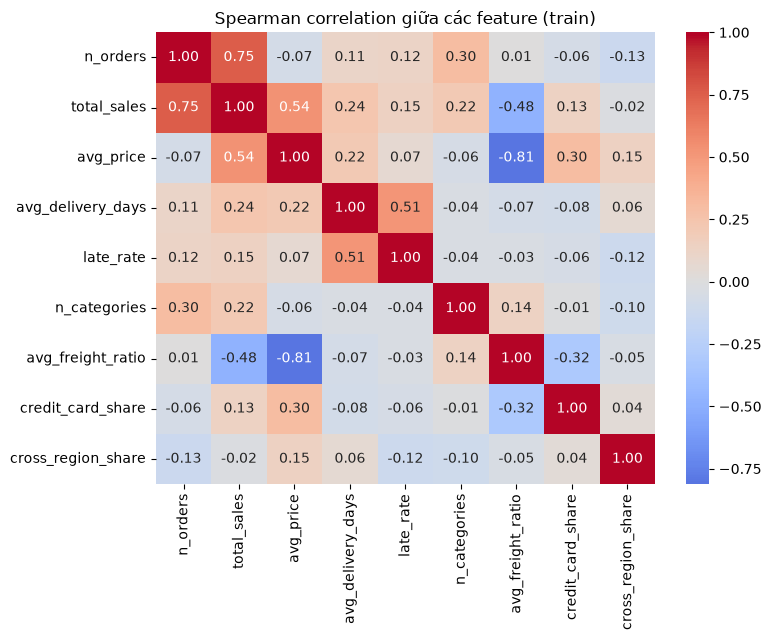

Mutual information với nhãn (train):


,MI
late_rate,0.0732
avg_delivery_days,0.0528
avg_price,0.0130
credit_card_share,0.0128
n_orders,0.0000
total_sales,0.0000
n_categories,0.0000
avg_freight_ratio,0.0000
cross_region_share,0.0000


Loại do tương quan cao: [('avg_freight_ratio', '|ρ(avg_freight_ratio,avg_price)|=0.81>0.8, MI thấp hơn')]
NUM2 = ['n_orders', 'total_sales', 'avg_price', 'avg_delivery_days', 'late_rate', 'n_categories', 'credit_card_share', 'cross_region_share']


In [21]:
from sklearn.feature_selection import mutual_info_classif

# 1) Tương quan Spearman giữa các feature số (chỉ dùng train)
corr = tr[NUM].corr(method='spearman')
plt.figure(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Spearman correlation giữa các feature (train)')
plt.tight_layout()
plt.savefig(FIG / 'mining_corr.png', dpi=130)
plt.show()

# 2) Mutual information của từng feature với nhãn
mi_values = mutual_info_classif(tr[NUM], tr.y, random_state=0)
mi = pd.Series(mi_values, index=NUM)
print('Mutual information với nhãn (train):')
display(mi.sort_values(ascending=False).round(4).to_frame('MI'))

# 3) Với mỗi cặp có |rho| > 0.8: loại feature có MI thấp hơn
dropped_corr = []
for a in NUM:
    for b in NUM:
        if a < b and abs(corr.loc[a, b]) > 0.8:
            if mi[a] < mi[b]:
                drop = a
            else:
                drop = b
            reason = f'|ρ({a},{b})|={abs(corr.loc[a, b]):.2f}>0.8, MI thấp hơn'
            dropped_corr.append((drop, reason))

if len(dropped_corr) > 0:
    print('Loại do tương quan cao:', dropped_corr)
else:
    print('Loại do tương quan cao: không có cặp nào > 0,8')

dropped_names = [d[0] for d in dropped_corr]
NUM2 = [c for c in NUM if c not in dropped_names]
print('NUM2 =', NUM2)

### 5.1.3 Rời rạc hoá và lọc item hiếm (*feature-minsup*)  *(Bảng 5.3)*

**Mục đích:** Chuyển bảng số thành ma trận item để khai phá, đồng thời loại item quá hiếm để luật không dựa trên vài seller.

**Cách làm:**
1. `fit_cut_points(tr, NUM2)` — mốc cắt tam phân vị học trên train; `to_items` áp mốc này cho train (`Itr`) và test (`Ite`).
2. `to_onehot` → ma trận bool `Btr` (train, có item lớp) và `Bte` (test). Cột của `Bte` được căn theo `Btr` (item nào test không có thì = False) để hai ma trận cùng cấu trúc.
3. **Feature-minsup = 5%:** item (feature=mức) phủ **dưới 5% seller train** bị loại khỏi khai phá (*rare item*). Hai item lớp được miễn loại. Với mức chia tam phân vị, chỉ các item *vùng hiếm* bị loại. Thường đó là các vùng nhỏ (ví dụ Northeast, Center-West); cell in danh sách cụ thể.

**Output:** `Btr`, `Bte`, `Btr_m` (đã bỏ item hiếm), `rare` (danh sách item bị loại), `N` (số seller train).

**Cách đọc:** Xem danh sách `rare`: những vùng nhỏ không thể xuất hiện trong luật >> để sử dụng cho luật về seller ở các vùng này.

In [23]:
# Rời rạc hoá: mốc cắt học trên train, áp dụng cho cả train và test
cuts = fit_cut_points(tr, NUM2)
Itr = to_items(tr, cuts, CAT)
Ite = to_items(te, cuts, CAT)

Btr = to_onehot(Itr, tr.y)                 # ma trận item của train (có item lớp)
Bte = to_onehot(Ite, te.y)                 # ma trận item của test
Bte = Bte.reindex(columns=Btr.columns, fill_value=False)    # căn cột test theo train
N = len(Btr)

print('Mốc cắt tam phân vị (học trên train):')
cut_table = {}
for col in NUM2:
    if len(cuts[col]) > 2:
        cut_table[col] = [round(x, 3) for x in cuts[col][1:-1]]
display(pd.DataFrame(cut_table, index=['mốc Low|Medium', 'mốc Medium|High']).T)

# Feature-minsup: loại item (không phải item lớp) phủ dưới 5% seller train
FEATURE_MINSUP = 0.05
sup_item = Btr.mean()
rare = []
for item, sup in sup_item.items():
    if sup < FEATURE_MINSUP and item not in CLASS_ITEMS:
        rare.append(item)
print('Item bị loại do Feature-minsup:', rare)

Btr_m = Btr.drop(columns=rare)
print(f'Số item: {Btr.shape[1]} -> {Btr_m.shape[1]} sau khi loại item hiếm')
display(sup_item.drop(rare).sort_values(ascending=False).round(3).to_frame('support').T)

Mốc cắt tam phân vị (học trên train):


,mốc Low|Medium,mốc Medium|High
n_orders,19.000,50.000
total_sales,2224.950,7058.000
avg_price,71.110,132.060
avg_delivery_days,10.200,13.154
late_rate,0.032,0.080
n_categories,2.000,3.000
credit_card_share,0.727,0.800
cross_region_share,0.309,0.417


Item bị loại do Feature-minsup: ['seller_region=Northeast', 'seller_region=Center-West']
Số item: 30 -> 28 sau khi loại item hiếm


,seller_region=Southeast,Performance=Good,n_categories=Low,n_orders=Low,cross_region_share=Medium,credit_card_share=Low,avg_delivery_days=Low,cross_region_share=Low,total_sales=Low,late_rate=Low,avg_price=Low,avg_price=High,late_rate=Medium,total_sales=Medium,avg_price=Medium,avg_delivery_days=High,total_sales=High,late_rate=High,avg_delivery_days=Medium,credit_card_share=Medium,credit_card_share=High,n_orders=High,cross_region_share=High,n_orders=Medium,n_categories=High,Performance=NeedsSupport,seller_region=South,n_categories=Medium
support,0.76,0.751,0.547,0.351,0.338,0.336,0.335,0.334,0.334,0.334,0.334,0.333,0.333,0.333,0.333,0.333,0.333,0.333,0.332,0.332,0.332,0.329,0.328,0.319,0.303,0.249,0.193,0.15


### 5.1.4 Kiểm định đơn biến các đặc trưng theo nhãn *(Bảng 5.4 trong bản Word)*

**Mục đích.** Trước khi khai phá luật, kiểm tra từng feature có *tách được* hai lớp Good / NeedsSupport hay không, để biết luật sẽ xoay quanh biến nào.

**Cách làm:** Feature số: **Mann–Whitney U** + cỡ ảnh hưởng *rank-biserial* (`1 − 2U/(n₁n₀)`); `seller_region`: **χ²**. Dùng toàn bộ seller đủ ngưỡng; **chưa hiệu chỉnh đa kiểm định**.

**Kết quả:** `avg_delivery_days` và `late_rate`: |r| ≈ 0,43, p < 1e-29 → khác biệt rất mạnh. `credit_card_share` (p khoảng 0,007) và `cross_region_share` (p khoảng 0,039) có ý nghĩa nhưng hiệu ứng nhỏ (|r| ≈ 0,08–0,10). Quy mô, giá, số ngành hàng không phân biệt được hai lớp; `seller_region` chưa đạt mức 5% (p khoảng 0,066). 

In [24]:
from scipy import stats

# Bảng 5.4: kiểm định từng feature giữa hai lớp (toàn bộ seller)
good = s[s.y == 1]
needs = s[s.y == 0]
n1, n0 = len(good), len(needs)

rows = []
for col in NUM2:
    u, p = stats.mannwhitneyu(good[col], needs[col])
    effect = 1 - 2 * u / (n1 * n0)                 # rank-biserial: cỡ ảnh hưởng
    rows.append({'feature': col, 'test': 'Mann-Whitney U', 'effect_rank_biserial': round(effect, 3), 'p_value': p})

chi, p, _, _ = stats.chi2_contingency(pd.crosstab(s.seller_region, s.y))
rows.append({'feature': 'seller_region', 'test': 'Chi-square', 'effect_rank_biserial': np.nan, 'p_value': p})

FS = pd.DataFrame(rows)
FS['p_value'] = [f'{v:.2e}' for v in FS.p_value]
display(FS)
FS.to_csv(OUT / 'feature_tests.csv', index=False)

,feature,test,effect_rank_biserial,p_value
0,n_orders,Mann-Whitney U,-0.022,5.57e-01
1,total_sales,Mann-Whitney U,0.014,7.16e-01
2,avg_price,Mann-Whitney U,-0.012,7.62e-01
3,avg_delivery_days,Mann-Whitney U,0.431,6.98e-30
4,late_rate,Mann-Whitney U,0.432,2.70e-30
5,n_categories,Mann-Whitney U,-0.009,8.05e-01
6,credit_card_share,Mann-Whitney U,-0.102,7.40e-03
7,cross_region_share,Mann-Whitney U,-0.078,3.92e-02
8,seller_region,Chi-square,NaN,6.56e-02


## 5.2 Chọn minsup toàn cục và minconf theo lớp  *(Hình 5.2, Bảng 5.5)*

**Mục đích:** Chọn **một** ngưỡng support dùng chung cho cả hai lớp (minsup *toàn cục*, tính trên toàn bộ |D| = N), đủ thấp để còn luật nhưng đủ cao để luật không nhiễu.

**Cách làm:** Với `minsup ∈ {1%, 2%, 3%, 5%, 8%, 10%}`: chạy FP-Growth, sinh CAR với `minconf = {Good 0,5; NeedsSupport 0,4}` và đếm số CAR mỗi lớp. Vẽ đồ thị (trục tung log).

**Chọn tham số cuối:** `MINSUP = 0,05`, `MINCONF = {Good: 0,60; NeedsSupport: 0,40}`.
- Lớp *Good* chiếm ~76% nên confidence 0,6 vẫn còn yếu (luật lift < 1 sẽ bị loại ở bước chọn luật).
- Lớp *NeedsSupport* chỉ ~24% nên confidence 0,4 đã tương ứng lift ≈ 1,7.

**Output.** Bảng `sweep`, hình `figs/mining_minsup.png`, hằng `MINSUP`, `MINCONF`.

**Cách đọc & lưu ý quan trọng.** Quan sát cột `CAR_NeedsSupport`: **minsup toàn cục khiến lớp thiểu số có rất ít luật** — so sánh hai cột `CAR_Good` và `CAR_NeedsSupport` ở dòng minsup = 5% (support của luật ≤ P(lớp) ≈ 24%, còn tổ hợp 2–3 item chỉ phủ vài %). Đây là *điểm yếu thật* của minsup toàn cục; mục 6.5 sẽ giải quyết bằng minsup *theo lớp*.

,minsup,n_itemsets,CAR_Good,CAR_NeedsSupport
0,0.01,9981,2041,233
1,0.02,6024,1591,136
2,0.03,3979,1152,88
3,0.05,1724,585,25
4,0.08,769,272,8
5,0.10,459,132,5


==> Chọn MINSUP toàn cục = 0.05, MINCONF = {'Good': 0.6, 'NeedsSupport': 0.4}


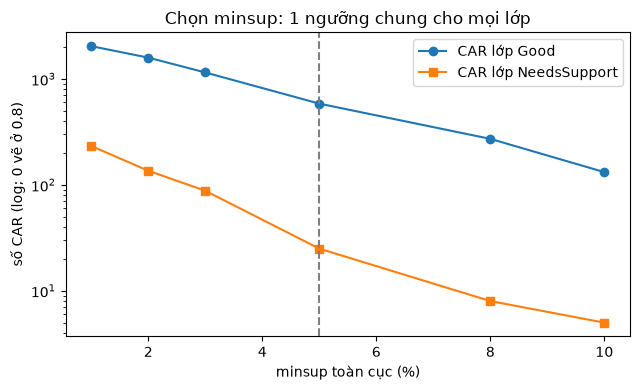

In [26]:
# Quét minsup: đếm số itemset và số luật (CAR) mỗi lớp
sweep_rows = []
for minsup in [0.01, 0.02, 0.03, 0.05, 0.08, 0.10]:
    fi = mine_fpgrowth(Btr_m, minsup)
    cars = gen_cars(fi, N, {'Good': 0.5, 'NeedsSupport': 0.4})
    if len(cars) > 0:
        n_good = (cars.cls == 'Good').sum()
        n_needs = (cars.cls == 'NeedsSupport').sum()
    else:
        n_good, n_needs = 0, 0
    sweep_rows.append({'minsup': minsup, 'n_itemsets': len(fi), 'CAR_Good': n_good, 'CAR_NeedsSupport': n_needs})
sweep = pd.DataFrame(sweep_rows)
display(sweep)

# Tham số được chọn
MINSUP = 0.05
MINCONF = {'Good': 0.60, 'NeedsSupport': 0.40}
print(f'==> Chọn MINSUP toàn cục = {MINSUP}, MINCONF = {MINCONF}')

# Hình 5.2 (trục tung log; giá trị 0 được vẽ ở mức 0,8 để hiện được trên thang log)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(sweep.minsup * 100, sweep.CAR_Good.clip(lower=0.8), 'o-', label='CAR lớp Good')
ax.plot(sweep.minsup * 100, sweep.CAR_NeedsSupport.clip(lower=0.8), 's-', label='CAR lớp NeedsSupport')
ax.axvline(MINSUP * 100, ls='--', c='gray')
ax.set_yscale('log')
ax.set_xlabel('minsup toàn cục (%)')
ax.set_ylabel('số CAR (log; 0 vẽ ở 0,8)')
ax.set_title('Chọn minsup: 1 ngưỡng chung cho mọi lớp')
ax.legend()
plt.tight_layout()
plt.savefig(FIG / 'mining_minsup.png', dpi=130)
plt.show()

## 5.3 So sánh các thuật toán khai phá  *(Bảng 5.6, 5.7)*

**Mục đích:** Khai phá tập phổ biến bằng Apriori, FP-Growth, ECLAT (tự cài đặt) và CHARM-closed; đo thời gian; kiểm chứng ECLAT cài đúng.

**Cách làm:**
1. Chạy 3 thuật toán đầu trên `Btr_m` với `MINSUP`, ghi thời gian.
2. **Phép thử tính đúng:** so sánh tập itemset của 3 thuật toán => phải **bằng nhau tuyệt đối** (`True`). Nếu `False`, cài đặt có lỗi.
3. `closed_filter` trên kết quả FP-Growth → **tập đóng** (CHARM-closed); in tỷ lệ so với tập phổ biến đầy đủ.

**Output:** `res` (từ điển thuật toán → bảng itemset), `t` (thời gian), `fi_full`.

**Cách đọc:** Thời gian chỉ có giá trị *tham khảo* (dữ liệu nhỏ, hàng nghìn itemset, chênh lệch mili-giây; ECLAT thuần Python chậm hơn thư viện C/Cython không có nghĩa là thuật toán kém). Tỷ lệ tập đóng cho biết mức *dư thừa* của tập phổ biến: càng thấp, càng nhiều itemset chỉ là "bản sao" của tập đóng cùng support.

In [28]:
# Chạy 3 thuật toán trên cùng ma trận, ghi thời gian
res = {}
t = {}
for name, mine_function in ALGOS.items():
    start = time.time()
    res[name] = mine_function(Btr_m, MINSUP)
    t[name] = time.time() - start
fi_full = res['FP-Growth']

# Kiểm tra: 3 thuật toán phải cho đúng cùng tập itemset
itemset_sets = {}
for name, fi in res.items():
    itemset_sets[name] = set([frozenset(x) for x in fi.itemsets])
print('Số itemset phổ biến:', {name: len(fi) for name, fi in res.items()})
same = itemset_sets['Apriori'] == itemset_sets['FP-Growth'] == itemset_sets['ECLAT']
print('3 thuật toán cho CÙNG tập itemset?', same)

# Tập đóng (CHARM-closed)
res['CHARM-closed (advanced)'] = closed_filter(fi_full)
n_closed = len(res['CHARM-closed (advanced)'])
print(f'Tập đóng (CHARM-closed): {n_closed} ({n_closed / len(fi_full):.0%} của tập phổ biến)')
display(pd.Series(t, name='thời gian (s)').round(4).to_frame())

Số itemset phổ biến: {'Apriori': 1724, 'FP-Growth': 1724, 'ECLAT': 1724}
3 thuật toán cho CÙNG tập itemset? True
Tập đóng (CHARM-closed): 1520 (88% của tập phổ biến)


,thời gian (s)
Apriori,0.0229
FP-Growth,0.0511
ECLAT,0.0156


## 5.4 Các luật được chọn: 9 luật chính + 3 luật CHARM-closed  *(Bảng 5.8)*

**Mục đích:** Với mỗi thuật toán, sinh CAR rồi chọn 3 luật tiêu biểu theo chiến lược xếp hạng riêng của thuật toán đó, để so sánh các cách tiếp cận.

**Cách xếp hạng:**

| Thuật toán | Cách xếp hạng | Ghi chú |
|---|---|---|
| Apriori | `confidence → support` | kiểu CBA-RG |
| FP-Growth | `weighted χ²` | kiểu CMAR |
| ECLAT | `leverage` | chênh lệch so với độc lập |
| CHARM-closed | `wχ²` trên luật **đóng** và **đa chiều** (`min_len=2`: vế trái ≥ 2 thuộc tính) | loại luật 1 thuộc tính vốn dễ trùng |

**Cách làm:** `gen_cars` → `select_rules` (2 luật Good + 1 luật NeedsSupport, chống trùng độ phủ) → gắn tên thuật toán. Sau đó tính:
- `cover_train_%` và `cover_test_%`: % seller mà vế trái luật khớp trên train / test (độ phủ ổn định giữa hai tập là dấu hiệu luật *tổng quát hoá* tốt);
- `union_cover`: hợp độ phủ của 3 luật mỗi thuật toán.

**Cách đọc:** Với mỗi luật xem **lift** (phải > 1), **confidence** và **độ phủ**. Một luật confidence cao nhưng lift khoảng ~1 chỉ phản ánh tỷ lệ nền của lớp Good. Nếu cả 3 luật của một thuật toán thiên về một lớp, đó là hệ quả của minsup toàn cục (xem mục 5.2).

In [30]:
# Cách xếp hạng riêng của từng thuật toán: (cột xếp hạng, mô tả)
STRAT = {'Apriori': ('confidence', 'CBA-RG: conf → sup'),
         'FP-Growth': ('wchi2', 'CMAR: weighted χ²'),
         'ECLAT': ('leverage', 'leverage'),
         'CHARM-closed (advanced)': ('wchi2', 'wχ² trên luật ĐÓNG và ĐA CHIỀU (≥2 thuộc tính)')}

allrules = {}      # toàn bộ CAR của từng thuật toán
selected = {}      # 3 luật được chọn của từng thuật toán
for name, fi in res.items():
    is_charm = 'CHARM' in name
    if is_charm:
        cars = gen_cars(fi, N, MINCONF, full_fi=fi_full)     # support vế trái tra từ tập phổ biến đầy đủ
        min_len = 2                                          # CHARM: chỉ lấy luật có >= 2 thuộc tính ở vế trái
    else:
        cars = gen_cars(fi, N, MINCONF)
        min_len = 1
    allrules[name] = cars
    selected[name] = select_rules(cars, Btr_m, STRAT[name][0], min_len=min_len)
    selected[name].insert(0, 'algo', name)
    print(f'{name:26s}: {len(cars):4d} CAR -> chọn {len(selected[name])} luật  [{STRAT[name][1]}]')

tab = pd.concat(selected.values(), ignore_index=True)

# Độ phủ trên train/test và mô tả luật dạng chuỗi
Bte_m = Bte.reindex(columns=Btr_m.columns, fill_value=False)
tab['cover_train_%'] = [coverage(a, Btr_m) * 100 for a in tab.antecedent]
tab['cover_test_%'] = [coverage(a, Bte_m) * 100 for a in tab.antecedent]
tab['rule'] = [' ∧ '.join(a) + ' ⇒ ' + c for a, c in zip(tab.antecedent, tab.cls)]
display(tab[['algo', 'rule', 'support', 'confidence', 'lift', 'wchi2', 'cover_train_%', 'cover_test_%']].round(3))

Apriori                   :  573 CAR -> chọn 3 luật  [CBA-RG: conf → sup]
FP-Growth                 :  573 CAR -> chọn 3 luật  [CMAR: weighted χ²]
ECLAT                     :  573 CAR -> chọn 3 luật  [leverage]
CHARM-closed (advanced)   :  519 CAR -> chọn 3 luật  [wχ² trên luật ĐÓNG và ĐA CHIỀU (≥2 thuộc tính)]


,algo,rule,support,confidence,lift,wchi2,cover_train_%,cover_test_%
0,Apriori,avg_delivery_days=Low ∧ cross_region_share=Low ∧ late_rate=Low ⇒ Good,0.059,0.981,1.305,13.261,6.012,7.527
1,Apriori,avg_delivery_days=Low ∧ seller_region=Southeast ∧ total_sales=High ⇒ Good,0.058,0.980,1.305,12.904,5.896,5.376
2,Apriori,avg_delivery_days=High ∧ late_rate=High ∧ n_categories=Low ⇒ NeedsSupport,0.067,0.598,2.406,15.436,11.214,12.634
3,FP-Growth,avg_delivery_days=Low ⇒ Good,0.301,0.897,1.193,16.762,33.526,29.839
4,FP-Growth,avg_delivery_days=Low ∧ late_rate=Low ⇒ Good,0.175,0.921,1.225,14.404,18.960,17.204
5,FP-Growth,avg_delivery_days=High ∧ late_rate=High ⇒ NeedsSupport,0.105,0.572,2.303,20.298,18.382,20.430
6,ECLAT,avg_delivery_days=Low ⇒ Good,0.301,0.897,1.193,16.762,33.526,29.839
7,ECLAT,late_rate=Low ⇒ Good,0.297,0.889,1.183,13.573,33.410,32.258
8,ECLAT,avg_delivery_days=High ⇒ NeedsSupport,0.145,0.434,1.746,11.031,33.295,36.828
9,CHARM-closed (advanced),avg_delivery_days=Low ∧ late_rate=Low ⇒ Good,0.175,0.921,1.225,14.404,18.960,17.204


### 5.4.1 Tóm tắt theo thuật toán và độ phủ hợp  *(Bảng 5.6)*

**Mục đích:** Gộp số liệu so sánh 4 thuật toán (số itemset, số CAR, độ phủ hợp của 3 luật, thời gian) vào một bảng và lưu ra file để dùng trong báo cáo.

**Cách làm:** Với mỗi thuật toán, tính hợp độ phủ (`union_cover_3rules_%`): % seller khớp **ít nhất một** trong 3 luật (train).

**Cách đọc:** Hai thuật toán cho cùng tập itemset (Apriori/FP-Growth/ECLAT) sẽ có cùng `n_frequent_itemsets` và `n_CAR`; chúng chỉ khác nhau ở **luật được chọn** (do chiến lược xếp hạng khác nhau), không phải ở khả năng khai phá.

In [31]:
# Độ phủ HỢP của 3 luật mỗi thuật toán (tỷ lệ seller khớp ít nhất 1 luật)
union = {}
for algo, group in tab.groupby('algo', sort=False):
    covered = np.zeros(N, dtype=bool)
    for antecedent in group.antecedent:
        covered = covered | Btr_m[list(antecedent)].all(axis=1).values
    union[algo] = covered.mean() * 100
    print(f'  {algo}: hợp 3 luật phủ {union[algo]:.1f}% seller (train)')

# Lưu kết quả
tab.to_pickle(OUT / 'selected_rules.pkl')
pd.Series(t).to_csv(OUT / 'algo_time.csv')

time_ref = dict(t)
time_ref['CHARM-closed (advanced)'] = np.nan
summ = pd.DataFrame({'n_frequent_itemsets': {k: len(v) for k, v in res.items()},
                     'n_CAR': {k: len(v) for k, v in allrules.items()},
                     'union_cover_3rules_%': union,
                     'time_s(tham khảo)': time_ref})
display(summ.round(3))
summ.to_csv(OUT / 'algo_summary.csv')

  Apriori: hợp 3 luật phủ 22.5% seller (train)
  FP-Growth: hợp 3 luật phủ 51.9% seller (train)
  ECLAT: hợp 3 luật phủ 77.1% seller (train)
  CHARM-closed (advanced): hợp 3 luật phủ 42.1% seller (train)


,n_frequent_itemsets,n_CAR,union_cover_3rules_%,time_s(tham khảo)
Apriori,1724,573,22.543,0.023
FP-Growth,1724,573,51.908,0.051
ECLAT,1724,573,77.110,0.016
CHARM-closed (advanced),1520,519,42.081,NaN


### 5.4.2 Hình 5.3 - độ phủ của 12 luật  *(Bảng 5.10: ổn định train/test)*

**Mục đích:** Nhìn nhanh luật nào phủ nhiều seller, thuộc lớp nào.

**Cách đọc:** Thanh **xanh** = luật ⇒ *Good*, thanh **đỏ** = luật ⇒ *NeedsSupport*; nhãn cuối thanh ghi % seller khớp vế trái (train) và confidence. Luật phủ rộng + lift cao là luật hữu ích nhất để hành động (ví dụ chương trình hỗ trợ nhắm vào nhóm seller khớp luật NeedsSupport).

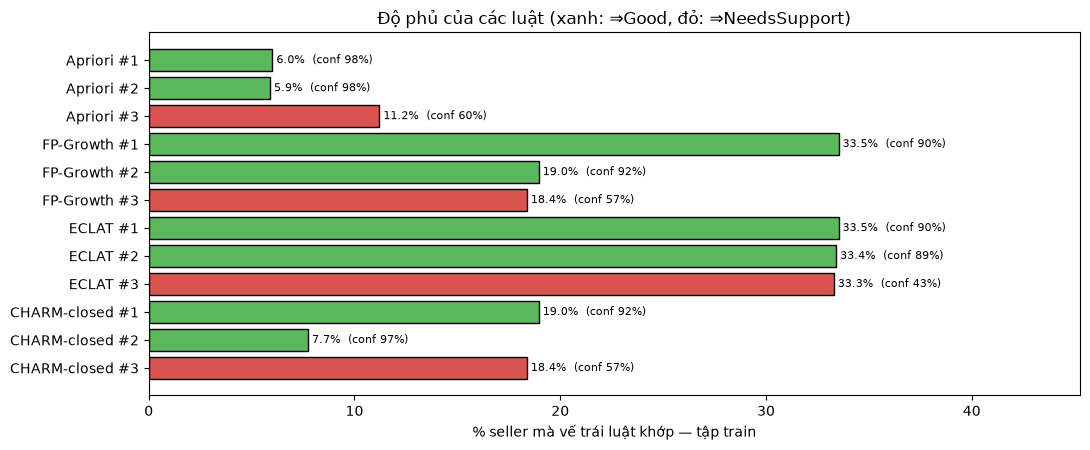

In [32]:
# Hình 5.3: độ phủ của các luật trên train (xanh: ⇒Good, đỏ: ⇒NeedsSupport)
plot_df = tab.copy()
plot_df['order_in_algo'] = plot_df.groupby('algo').cumcount() + 1
labels = []
for algo, k in zip(plot_df.algo, plot_df.order_in_algo):
    labels.append(algo.replace(' (advanced)', '') + ' #' + str(k))
colors = []
for cls in plot_df.cls:
    if cls == 'Good':
        colors.append('#5cb85c')
    else:
        colors.append('#d9534f')

# đảo thứ tự để luật đầu tiên nằm trên cùng
labels = labels[::-1]
colors = colors[::-1]
covers = list(plot_df['cover_train_%'])[::-1]
confs = list(plot_df.confidence)[::-1]

fig, ax = plt.subplots(figsize=(11, 4.6))
ax.barh(labels, covers, color=colors, edgecolor='k')
for i in range(len(covers)):
    ax.text(covers[i], i, f' {covers[i]:.1f}%  (conf {confs[i]:.0%})', va='center', fontsize=8)
ax.set_xlabel('% seller mà vế trái luật khớp — tập train')
ax.set_title('Độ phủ của các luật (xanh: ⇒Good, đỏ: ⇒NeedsSupport)')
ax.set_xlim(0, max(45, max(covers) * 1.35))
plt.tight_layout()
plt.savefig(FIG / 'rules_coverage.png', dpi=130)
plt.show()

---
# CHƯƠNG 6 - THIẾT KẾ, KẾT QUẢ PHÂN LỚP VÀ KIỂM ĐỊNH THỐNG KÊ

Thứ tự trình bày nhóm ghi theo word: 6.1 feature từ luật → 6.2 thiết kế thực nghiệm → 6.3 kết quả và kiểm định → phần mở rộng.

## 6.1 Bài toán và feature từ luật: bảng feature trước / sau khai phá  *(Bảng 6.1, 6.2)*

**Mục đích:** Trả lời "khai phá luật cho ta biết feature nào *đáng giữ*?" bằng một quy tắc rõ ràng.

**Quy tắc quyết định cho từng feature ban đầu:**
- **LOẠI** nếu bị loại ở bước tương quan (mục 5.1.2);
- **LOẠI** nếu **không xuất hiện** trong bất kỳ CAR *có ý nghĩa* nào (`lift > 1` và `χ² ≥ 3,84`) của cả 4 thuật toán;
- **GIỮ** nếu xuất hiện trong ≥ 1 CAR có ý nghĩa. Cột ghi chú đánh dấu feature có mặt trong 3 luật được chọn của Apriori/FP-Growth.

**Output:** Bảng `ft` (`out/feature_table.csv`) //  `NUM2`, `MINSUP`, `MINCONF`, danh sách item hiếm, feature giữ lại) cho các bước sau.

**Cách đọc:** Số feature *sau lọc* + 3 feature luật cho biết "kích thước" bộ đặc trưng cuối. Lưu ý đây là **bộ lọc theo luật**, không phải bằng chứng nhân quả; feature bị LOẠI vẫn có thể hữu ích cho mô hình ở dạng liên tục (mục 6.2 vẫn dùng toàn bộ `NUM2 + CAT` làm baseline).

In [33]:
# Thuộc tính xuất hiện trong 3 luật được chọn của Apriori và FP-Growth
used_attrs = set()
rules_12 = tab[tab.algo.isin(['Apriori', 'FP-Growth'])]
for antecedent in rules_12.antecedent:
    for item in antecedent:
        used_attrs.add(item.split('=')[0])

# Thuộc tính xuất hiện trong ít nhất 1 CAR có ý nghĩa (lift > 1 và χ² >= 3.84)
in_cars = set()
for cars in allrules.values():
    if len(cars) == 0:
        continue
    significant = cars[(cars.lift > 1) & (cars.chi2 >= 3.84)]
    for antecedent in significant.antecedent:
        for item in antecedent:
            in_cars.add(item.split('=')[0])

rows = []
for feature in N_BEFORE:
    if feature in dropped_names:
        status, reason = 'LOẠI', 'tương quan cao với feature khác'
    elif feature not in in_cars:
        status, reason = 'LOẠI', 'không xuất hiện trong CAR có ý nghĩa (lift>1, χ²≥3.84)'
    else:
        status, reason = 'GIỮ', 'xuất hiện trong ≥1 CAR có ý nghĩa'
    note = 'có trong 3 luật chọn' if feature in used_attrs else ''
    rows.append((feature, status, reason, note))

ft = pd.DataFrame(rows, columns=['feature', 'trạng thái', 'lý do', 'ghi chú'])
display(ft)
ft.to_csv(OUT / 'feature_table.csv', index=False)

n_keep = (ft['trạng thái'] == 'GIỮ').sum()
print(f'Số feature: trước = {len(N_BEFORE)} | sau lọc = {n_keep} | + 3 feature luật = {n_keep + 3}')

mining_meta = {'NUM2': NUM2, 'CAT': CAT, 'MINSUP': MINSUP, 'MINCONF': MINCONF, 'sweep': sweep,
               'dropped_corr': dropped_corr, 'rare': rare,
               'kept': ft[ft['trạng thái'] == 'GIỮ'].feature.tolist()}
with open(OUT / 'mining_meta.pkl', 'wb') as f:
    pickle.dump(mining_meta, f)

,feature,trạng thái,lý do,ghi chú
0,n_orders,GIỮ,xuất hiện trong ≥1 CAR có ý nghĩa,
1,total_sales,GIỮ,xuất hiện trong ≥1 CAR có ý nghĩa,có trong 3 luật chọn
2,avg_price,GIỮ,xuất hiện trong ≥1 CAR có ý nghĩa,
3,avg_delivery_days,GIỮ,xuất hiện trong ≥1 CAR có ý nghĩa,có trong 3 luật chọn
4,late_rate,GIỮ,xuất hiện trong ≥1 CAR có ý nghĩa,có trong 3 luật chọn
5,n_categories,GIỮ,xuất hiện trong ≥1 CAR có ý nghĩa,có trong 3 luật chọn
6,avg_freight_ratio,LOẠI,tương quan cao với feature khác,
7,credit_card_share,GIỮ,xuất hiện trong ≥1 CAR có ý nghĩa,
8,cross_region_share,GIỮ,xuất hiện trong ≥1 CAR có ý nghĩa,có trong 3 luật chọn
9,seller_region,GIỮ,xuất hiện trong ≥1 CAR có ý nghĩa,có trong 3 luật chọn


Số feature: trước = 10 | sau lọc = 9 | + 3 feature luật = 12


## 6.2 Thiết kế thực nghiệm và kiểm soát rò rỉ dữ liệu  *(Bảng 6.4, 6.5)*

**Câu hỏi nghiên cứu:** Khi thêm các luật đã khai phá làm đặc trưng, mô hình dự đoán Good/NeedsSupport có tốt hơn *baseline* không?

**Thiết kế thực nghiệm:**
- **Cross-validation lặp:** `RepeatedStratifiedKFold` 5 fold × 3 lần lặp = **15 lần đánh giá**, phân tầng theo nhãn.
- **Mining nằm TRONG từng fold:** rời rạc hoá → lọc item hiếm → khai phá → chọn luật đều chỉ dùng phần train của fold đó; test chỉ *áp dụng* luật. Đây là điểm mà nhiều bài làm sai (khai phá luật trên toàn bộ dữ liệu rồi mới CV ⇒ **rò rỉ**, kết quả lạc quan giả).
- **7 cấu hình đặc trưng × 3 mô hình** (Logistic Regression có chuẩn hoá, Decision Tree sâu 4, Random Forest 150 cây).
- **Các chỉ số:** accuracy, precision, recall, F1 (lớp Good), **macro-F1** và **recall lớp NeedsSupport** (quan trọng vì lớp thiểu số), AUC.

### 6.2.1 Mô hình, hàm tạo đặc trưng luật và hàm đánh giá

**Mục đích:** Chuẩn bị các thành phần dùng lại ở mục 10–13.

**Thành phần:**
- `MODELS`: 3 mô hình. `LogReg` đi kèm `StandardScaler` (vì feature có thang đo rất khác nhau, vd `total_sales` hàng nghìn so với `late_rate` ≤ 1); cây và rừng không cần chuẩn hoá.
- `RULE_SETUPS`: 4 cấu hình khai phá (thuật toán, ranker, độ dài tối thiểu) khớp với mục 5.4.
- `base_matrix`: ma trận feature gốc — feature số giữ nguyên, `seller_region` one-hot (tính trên train+test cùng lúc *chỉ để thống nhất tên cột*, không dùng thông tin nhãn nên không rò rỉ).
- **`rule_features(Xtr, ytr, Xte)`**: toàn bộ pipeline mining chạy **chỉ trên train** → trả về cột đặc trưng luật cho train và test cho cả 4 cấu hình + RuleScore.
- `evaluate`: huấn luyện, dự đoán, trả về 7 chỉ số.

In [34]:
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from scipy import stats

X_all = s[NUM2 + CAT]          # feature (không có avg_review)
y_all = s.y

MODEL_NAMES = ['LogReg', 'DecisionTree', 'RandomForest']


def make_model(name):
    """Tạo mô hình mới (chưa fit) theo tên."""
    if name == 'LogReg':
        return make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    if name == 'DecisionTree':
        return DecisionTreeClassifier(max_depth=4, min_samples_leaf=10, random_state=0)
    if name == 'RandomForest':
        return RandomForestClassifier(n_estimators=150, min_samples_leaf=5, random_state=0, n_jobs=-1)


# 4 cách chọn luật: tên -> (thuật toán, cột xếp hạng, độ dài tối thiểu vế trái)
RULE_SETUPS = {'Apriori+CBA': ('Apriori', 'confidence', 1),
               'FPGrowth+CMAR': ('FP-Growth', 'wchi2', 1),
               'ECLAT+leverage': ('ECLAT', 'leverage', 1),
               'CHARM-closed (adv)': ('CHARM', 'wchi2', 2)}


def base_matrix(X_train, X_test):
    """Feature gốc: one-hot cột seller_region (get_dummies làm trên cả train+test, không dùng nhãn)."""
    both = pd.concat([X_train, X_test])
    dummies = pd.get_dummies(both, columns=CAT, dtype=float)
    return dummies.loc[X_train.index], dummies.loc[X_test.index]


def prepare_items(X_train, y_train, X_test):
    """Rời rạc hoá + one-hot + loại item hiếm. Mọi thứ HỌC chỉ từ train; test chỉ được áp dụng lại."""
    cut_points = fit_cut_points(X_train, NUM2)
    B_train = to_onehot(to_items(X_train, cut_points, CAT), y_train)
    B_test = to_onehot(to_items(X_test, cut_points, CAT))
    B_test = B_test.reindex(columns=B_train.columns, fill_value=False)

    keep = []
    for col in B_train.columns:
        if col in CLASS_ITEMS or B_train[col].mean() >= FEATURE_MINSUP:
            keep.append(col)
    return B_train[keep], B_test[keep]


def rule_features(X_train, y_train, X_test):
    """Khai phá luật CHỈ trên train, rồi tạo feature luật cho train và test.
    Trả về dict: tên cấu hình -> (feature_train, feature_test)."""
    B_train, B_test = prepare_items(X_train, y_train, X_test)
    n_train = len(B_train)

    frequent = {}
    frequent['FP-Growth'] = mine_fpgrowth(B_train, MINSUP)
    cars_by_setup = {}
    features = {}

    for name, (algo, ranker, min_len) in RULE_SETUPS.items():
        if algo == 'CHARM':
            frequent['CHARM'] = closed_filter(frequent['FP-Growth'])
            cars = gen_cars(frequent['CHARM'], n_train, MINCONF, full_fi=frequent['FP-Growth'])
        else:
            if algo not in frequent:
                frequent[algo] = ALGOS[algo](B_train, MINSUP)
            cars = gen_cars(frequent[algo], n_train, MINCONF)
        cars_by_setup[name] = cars
        chosen = select_rules(cars, B_train, ranker, min_len=min_len)
        features[name] = (rules_to_features(chosen, B_train), rules_to_features(chosen, B_test))

    # RuleScore (phương pháp đề xuất): dùng các CAR của FP-Growth
    cars_fp = cars_by_setup['FPGrowth+CMAR']
    features['RuleScore (mới)'] = (rule_score_features(cars_fp, B_train), rule_score_features(cars_fp, B_test))
    return features


def evaluate(model, X_train, y_train, X_test, y_test):
    """Fit mô hình, dự đoán trên test, trả về dict các chỉ số."""
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    result = {'accuracy': accuracy_score(y_test, pred),
              'precision': precision_score(y_test, pred),
              'recall': recall_score(y_test, pred),
              'f1': f1_score(y_test, pred),
              'macro_f1': f1_score(y_test, pred, average='macro'),
              'recall_NeedsSupport': recall_score(y_test, pred, pos_label=0),
              'auc': roc_auc_score(y_test, proba)}
    return result, pred


print('Sẵn sàng:', MODEL_NAMES, '|', list(RULE_SETUPS))

Sẵn sàng: ['LogReg', 'DecisionTree', 'RandomForest'] | ['Apriori+CBA', 'FPGrowth+CMAR', 'ECLAT+leverage', 'CHARM-closed (adv)']


### 6.2.2 Chạy cross-validation 15 fold (≈ 1 phút)

**Mục đích:** So sánh 7 cấu hình đặc trưng × 3 mô hình trên cùng 15 fold (so sánh *ghép cặp* — cùng fold cho mọi cấu hình, điều kiện cần của các kiểm định ở mục 6.3.3).

**7 cấu hình:**
| # | Cấu hình | Ý nghĩa |
|---|---|---|
| 0 | Không luật (baseline) | chỉ feature gốc (`NUM2` + vùng one-hot) |
| 1–4 | Baseline + 3 luật của Apriori / FP-Growth / ECLAT / CHARM-closed | feature gốc + 3 cột nhị phân từ luật |
| 5 | Chỉ 3 feature luật (Apriori) | đo xem **riêng luật** có đủ dự đoán không |
| 6 | Baseline + RuleScore | feature gốc + 3 điểm liên tục (phương pháp đề xuất) |

**Cách làm:** Với mỗi fold: tách train/test → `rule_features` (mining chỉ trên train) → ghép đặc trưng → huấn luyện 3 mô hình → ghi các chỉ số. Mỗi 5 fold in tiến độ.

**Output.** `R` (15 fold × 7 × 3 = 315 dòng).

In [35]:
# Cross-validation 5 fold x 3 lần lặp = 15 fold. Luật được khai phá lại BÊN TRONG từng fold.
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED_CV)
records = []
start = time.time()

for fold, (train_idx, test_idx) in enumerate(cv.split(X_all, y_all)):
    X_train, X_test = X_all.iloc[train_idx], X_all.iloc[test_idx]
    y_train, y_test = y_all.iloc[train_idx], y_all.iloc[test_idx]

    A_train, A_test = base_matrix(X_train, X_test)                  # feature gốc
    rf = rule_features(X_train, y_train, X_test)                    # feature từ luật (chỉ học từ train)

    # Các cấu hình feature cần so sánh: tên -> (ma trận train, ma trận test)
    settings = {}
    settings['0. Không luật (baseline)'] = (A_train, A_test)
    settings['5. Chỉ 3 feature luật (Apriori)'] = (rf['Apriori+CBA'][0], rf['Apriori+CBA'][1])

    number = 1
    for name in ['Apriori+CBA', 'FPGrowth+CMAR', 'ECLAT+leverage', 'CHARM-closed (adv)']:
        rule_train, rule_test = rf[name]
        settings[f'{number}. Baseline + {name}'] = (pd.concat([A_train, rule_train], axis=1),
                                                   pd.concat([A_test, rule_test], axis=1))
        number += 1

    score_train, score_test = rf['RuleScore (mới)']
    settings['6. Baseline + RuleScore (phương pháp mới)'] = (pd.concat([A_train, score_train], axis=1),
                                                            pd.concat([A_test, score_test], axis=1))

    for setting_name, (M_train, M_test) in settings.items():
        for model_name in MODEL_NAMES:
            metrics, _ = evaluate(make_model(model_name), M_train, y_train, M_test, y_test)
            record = {'fold': fold, 'setting': setting_name, 'model': model_name}
            record.update(metrics)
            records.append(record)

    if fold % 5 == 0:
        print(f'fold {fold} xong ({time.time() - start:.0f}s)', flush=True)

R = pd.DataFrame(records)
R.to_pickle(OUT / 'cv_results.pkl')
print('Xong', len(R), 'dòng kết quả,', f'{time.time() - start:.0f}s')

fold 0 xong (3s)
fold 5 xong (16s)
fold 10 xong (28s)
Xong 315 dòng kết quả, 37s


### 6.3.2 Bảng kết quả trung bình 15 fold  *(Bảng 6.7, 6.8, 6.9)*

**Chú ý:**
- So từng cấu hình với **dòng "0. Không luật"** *cùng mô hình*. Chênh lệch nhỏ (vài phần nghìn đến ~1 điểm %) chưa chắc thật — kiểm định thống kê ở mục 6.3.3 mới quyết định.
- **Accuracy dễ gây hiểu lầm** vì lớp Good chiếm ~76%: nhìn **macro-F1** và **recall_NeedsSupport** (khả năng phát hiện seller cần hỗ trợ).
- Dòng **"5. Chỉ 3 feature luật"** thường có recall NeedsSupport cao nhưng AUC thấp: 3 cột nhị phân quá nghèo thông tin để thay thế bộ feature gốc → luật *bổ sung* chứ không *thay thế*.
- Cột `auc` đánh giá khả năng xếp hạng, không phụ thuộc ngưỡng 0,5 — hữu ích khi lệch lớp.

accuracy  precision  recall      f1  macro_f1  recall_NeedsSupport     auc
model        setting                                                                                                              
DecisionTree 0. Không luật (baseline)                     0.7796     0.8001  0.9422  0.8651    0.6291               0.2890  0.6926
             1. Baseline + Apriori+CBA                    0.7780     0.7988  0.9419  0.8641    0.6256               0.2836  0.6903
             2. Baseline + FPGrowth+CMAR                  0.7785     0.7996  0.9412  0.8643    0.6279               0.2879  0.6915
             3. Baseline + ECLAT+leverage                 0.7796     0.8001  0.9422  0.8651    0.6291               0.2890  0.6927
             4. Baseline + CHARM-closed (adv)             0.7785     0.7996  0.9412  0.8643    0.6279               0.2879  0.6915
             5. Chỉ 3 feature luật (Apriori)              0.7626     0.7993  0.9135  0.8524    0.6214               0.3073  0.6484
             6. Baseline + RuleScore (phương pháp mới)    0.7782     0.8004  0.9390  0.8640    0.6297               0.2933  0.7058
LogReg       0. Không luật (baseline)                     0.7858     0.8014  0.9505  0.8695    0.6352               0.2890  0.7426
             1. Baseline + Apriori+CBA                    0.7885     0.8049  0.9483  0.8707    0.6441               0.3063  0.7494
             2. Baseline + FPGrowth+CMAR                  0.7874     0.8039  0.9483  0.8701    0.6417               0.3020  0.7440
             3. Baseline + ECLAT+leverage                 0.7887     0.8044  0.9498  0.8710    0.6432               0.3031  0.7414
             4. Baseline + CHARM-closed (adv)             0.7879     0.8048  0.9476  0.8703    0.6440               0.3063  0.7451
             5. Chỉ 3 feature luật (Apriori)              0.7626     0.7993  0.9135  0.8524    0.6214               0.3073  0.6484
             6. Baseline + RuleScore (phương pháp mới)    0.7890     0.8070  0.9454  0.8706    0.6484               0.3171  0.7441
RandomForest 0. Không luật (baseline)                     0.7887     0.8025  0.9534  0.8714    0.6393               0.2922  0.7239
             1. Baseline + Apriori+CBA                    0.7868     0.8032  0.9487  0.8698    0.6405               0.2987  0.7286
             2. Baseline + FPGrowth+CMAR                  0.7866     0.8024  0.9498  0.8698    0.6383               0.2944  0.7270
             3. Baseline + ECLAT+leverage                 0.7863     0.8009  0.9523  0.8699    0.6346               0.2858  0.7280
             4. Baseline + CHARM-closed (adv)             0.7866     0.8013  0.9519  0.8700    0.6358               0.2879  0.7255
             5. Chỉ 3 feature luật (Apriori)              0.7626     0.7993  0.9135  0.8524    0.6214               0.3073  0.6485
             6. Baseline + RuleScore (phương pháp mới)    0.7833     0.8054  0.9383  0.8666    0.6436               0.3160  0.7214

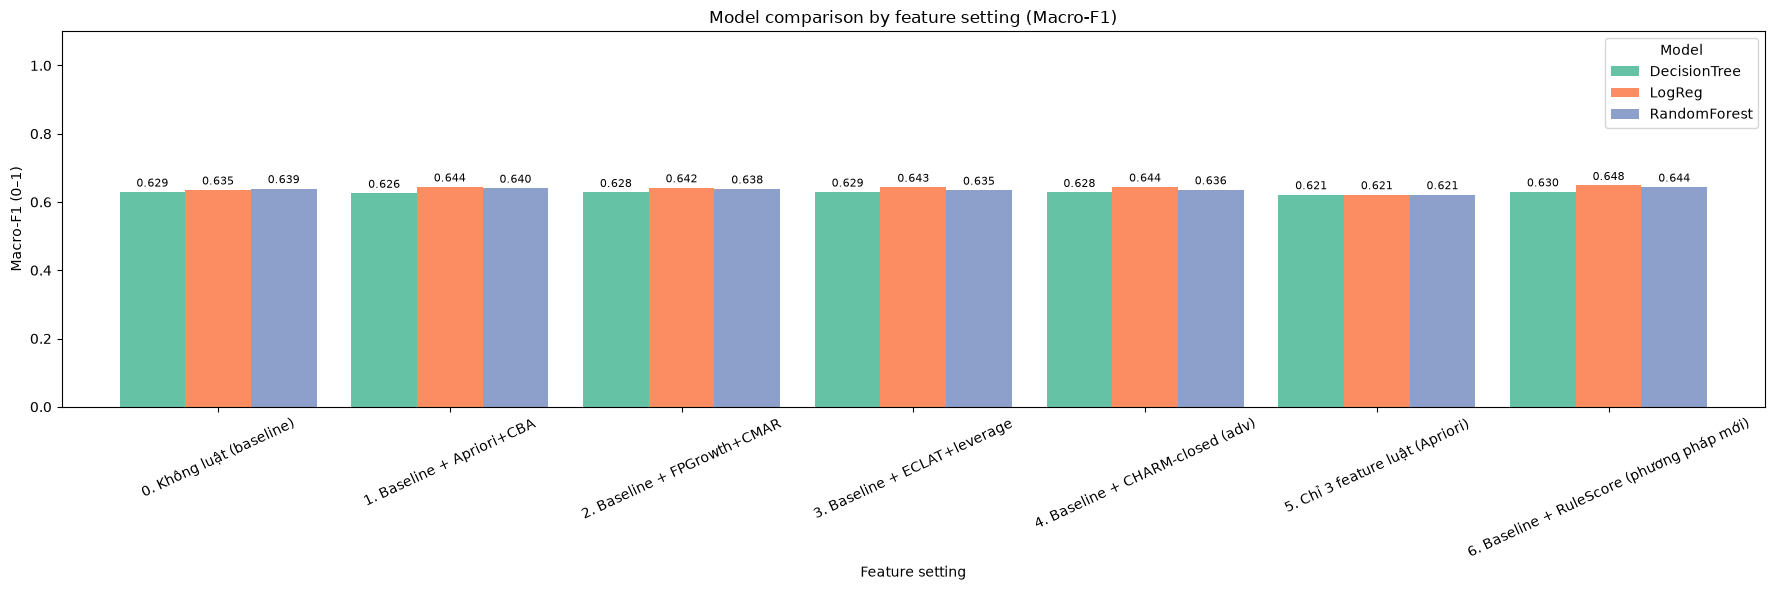

In [36]:
metric_cols = ['accuracy', 'precision', 'recall', 'f1', 'macro_f1', 'recall_NeedsSupport', 'auc']
summ_cv = R.groupby(['model', 'setting'])[metric_cols].mean().round(4)
display(summ_cv)
summ_cv.to_csv(OUT / 'cv_summary.csv')

# Biểu đồ cột so sánh macro-F1 giữa các cấu hình, mỗi mô hình một màu
macro_f1 = summ_cv['macro_f1'].unstack('model')
ax = macro_f1.plot(kind='bar', figsize=(18, 6), width=0.85, ylim=(0, 1.10),
                   color=sns.color_palette('Set2', n_colors=macro_f1.shape[1]))
for bars in ax.containers:
    ax.bar_label(bars, fmt='%.3f', padding=2, fontsize=8)
ax.set_title('Model comparison by feature setting (Macro-F1)')
ax.set_xlabel('Feature setting')
ax.set_ylabel('Macro-F1 (0–1)')
ax.legend(title='Model')
ax.tick_params(axis='x', labelrotation=25)
plt.tight_layout()
plt.show()

### 6.3.2b Hình 6.1 / 6.2 — Phân bố macro-F1 qua 15 fold

**Cách đọc:** Khác biệt trung bình nhỏ so với biến thiên giữa các fold; vì vậy cần kiểm định thống kê ở mục 6.3.3.

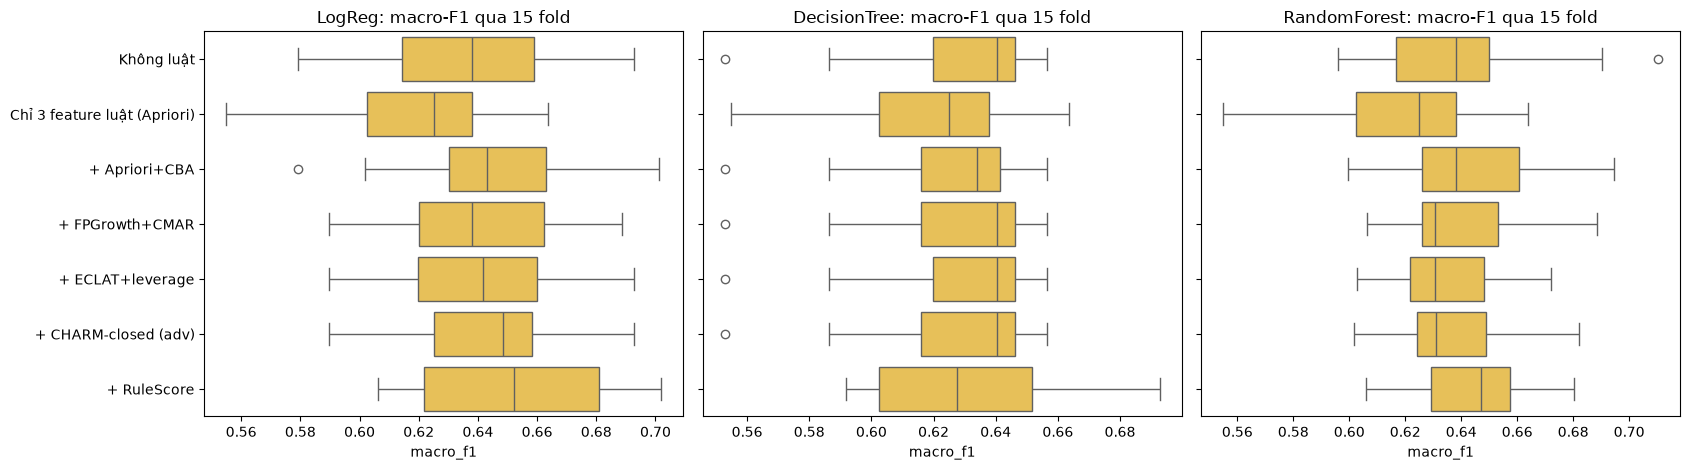

In [37]:
# Hình 6.1/6.2: boxplot macro-F1 qua 15 fold, mỗi mô hình một khung
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), sharey=True)
for ax, model_name in zip(axes, MODEL_NAMES):
    sub = R[R.model == model_name].copy()
    # rút gọn tên cấu hình cho dễ đọc
    sub['setting'] = sub.setting.str.replace(r'^\d\. ', '', regex=True)
    sub['setting'] = sub.setting.str.replace('Baseline + ', '+ ').str.replace(' (phương pháp mới)', '').str.replace(' (baseline)', '')
    sns.boxplot(data=sub, y='setting', x='macro_f1', ax=ax, color='#FFCA41')
    ax.set_title(f'{model_name}: macro-F1 qua 15 fold')
    ax.set_ylabel('')
plt.tight_layout()
plt.savefig(FIG / 'clf_boxplot.png', dpi=130)
plt.show()

## 6.3.3 Kiểm định thống kê so sánh cặp  *(Bảng 6.6, 6.10)*

Chênh lệch giữa các cấu hình thường nhỏ, nên cần kiểm định để biết **có thật** hay chỉ do ngẫu nhiên chia dữ liệu.

**12.1 Hold-out 70/30 + McNemar.** Dùng đúng split 70/30 ở mục 5.1, so 3 cấu hình (*không luật*, *+ 3 luật Apriori*, *+ 3 luật FP-Growth*). **McNemar (exact binomial)** so hai mô hình trên *cùng* tập test: đếm `b` = số seller chỉ baseline đoán đúng, `c` = số seller chỉ mô hình có luật đoán đúng; H0: b = c. *Hạn chế:* test chỉ tập test nhỏ (~370 seller) nên McNemar có **công suất thấp**; p lớn không chứng minh "không khác".

**12.2 Friedman trên 15 fold.** Kiểm định *omnibus* không tham số: 6 cấu hình có cùng phân phối macro-F1/F1 không? (so sánh nhiều nhóm ghép cặp).

**12.3 So sánh cặp với baseline**, ba cách để bù cho việc 15 fold *không độc lập* (các tập train chồng lấn nhau):
- **Wilcoxon signed-rank** (không tham số) và hiệu chỉnh **Holm** cho so sánh nhiều lần;
- **Nadeau–Bengio corrected resampled t-test**: phương sai hiệu chỉnh `(1/n + n_test/n_train)` — chuẩn cho CV lặp. Đây là kiểm định *thận trọng nhất*; nên ưu tiên khi kết luận.

**12.4 Kiểm định từng feature** Good vs NeedsSupport: Mann–Whitney U (feature số, kèm *rank-biserial* làm cỡ ảnh hưởng) và χ² (vùng).

**Kết luận:** chỉ khẳng định "luật cải thiện" khi cả Nadeau–Bengio và Holm-Wilcoxon cùng có ý nghĩa; nếu chỉ có Wilcoxon chưa hiệu chỉnh thì ghi là "xu hướng".

In [38]:
from statsmodels.stats.multitest import multipletests
from scipy import stats

base = '0. Không luật (baseline)'
compare = [name for name in R.setting.unique() if name[0] in '12346']      # 5 cấu hình có luật (bỏ cấu hình số 5)

# ---- Friedman trên 15 fold ----
friedman_rows = []
for model_name in MODEL_NAMES:
    for metric in ['f1', 'macro_f1']:
        sub = R[(R.model == model_name) & (R.setting.isin([base] + compare))]
        table = sub.pivot(index='fold', columns='setting', values=metric)     # hàng = fold, cột = cấu hình
        groups = [table[c] for c in table.columns]
        stat, p = stats.friedmanchisquare(*groups)
        friedman_rows.append({'model': model_name, 'metric': metric, 'friedman_chi2': round(stat, 3), 'p_value': round(p, 4)})
FR = pd.DataFrame(friedman_rows)
print('=== Friedman (6 cấu hình, 15 fold) ===')
display(FR)
FR.to_csv(OUT / 'friedman.csv', index=False)

# ---- So sánh cặp với baseline: Wilcoxon (+Holm) và Nadeau–Bengio ----
pair_rows = []
for model_name in MODEL_NAMES:
    table = R[R.model == model_name].pivot(index='fold', columns='setting', values='macro_f1')
    n = len(table)                                                            # 15 fold
    rows_model = []
    for setting in compare:
        diff = table[setting] - table[base]                                   # chênh lệch macro-F1 theo từng fold
        try:
            p_wilcoxon = stats.wilcoxon(diff).pvalue
        except ValueError:                                                    # mọi chênh lệch = 0
            p_wilcoxon = 1.0
        # Nadeau–Bengio: hiệu chỉnh phương sai vì các fold chồng lấn (n_test/n_train = 1/4)
        if diff.var(ddof=1) > 0:
            t_value = diff.mean() / np.sqrt((1 / n + 0.25) * diff.var(ddof=1))
        else:
            t_value = 0.0
        p_nb = 2 * stats.t.sf(abs(t_value), n - 1)
        rows_model.append({'model': model_name, 'setting': setting, 'Δmacro_F1': round(diff.mean(), 4),
                           'wilcoxon_p': p_wilcoxon, 'nadeau_bengio_p': p_nb})

    # Holm: hiệu chỉnh cho 5 phép so sánh của mỗi mô hình
    holm_p = multipletests([r['wilcoxon_p'] for r in rows_model], method='holm')[1]
    for r, p_holm in zip(rows_model, holm_p):
        r['wilcoxon_p_holm'] = round(p_holm, 4)
        r['wilcoxon_p'] = round(r['wilcoxon_p'], 4)
        r['nadeau_bengio_p'] = round(r['nadeau_bengio_p'], 4)
        pair_rows.append(r)

PW = pd.DataFrame(pair_rows)
print('=== So sánh cặp với baseline (Δ macro-F1) ===')
display(PW)
PW.to_csv(OUT / 'pairwise.csv', index=False)

=== Friedman (6 cấu hình, 15 fold) ===


,model,metric,friedman_chi2,p_value
0,LogReg,f1,4.065,0.5401
1,LogReg,macro_f1,13.141,0.0221
2,DecisionTree,f1,0.577,0.9890
3,DecisionTree,macro_f1,1.962,0.8544
4,RandomForest,f1,4.425,0.4900
5,RandomForest,macro_f1,3.929,0.5597


=== So sánh cặp với baseline (Δ macro-F1) ===


,model,setting,Δmacro_F1,wilcoxon_p,nadeau_bengio_p,wilcoxon_p_holm
0,LogReg,1. Baseline + Apriori+CBA,0.0090,0.0093,0.1845,0.0351
1,LogReg,2. Baseline + FPGrowth+CMAR,0.0065,0.0355,0.2871,0.0561
2,LogReg,3. Baseline + ECLAT+leverage,0.0080,0.0281,0.2533,0.0561
3,LogReg,4. Baseline + CHARM-closed (adv),0.0088,0.0088,0.1363,0.0351
4,LogReg,6. Baseline + RuleScore (phương pháp mới),0.0133,0.0046,0.0541,0.0232
5,DecisionTree,1. Baseline + Apriori+CBA,-0.0035,0.1088,0.4161,0.5440
6,DecisionTree,2. Baseline + FPGrowth+CMAR,-0.0012,0.3173,0.6534,1.0000
7,DecisionTree,3. Baseline + ECLAT+leverage,0.0000,NaN,1.0000,NaN
8,DecisionTree,4. Baseline + CHARM-closed (adv),-0.0012,0.3173,0.6534,1.0000
9,DecisionTree,6. Baseline + RuleScore (phương pháp mới),0.0007,0.9780,0.9677,1.0000


In [39]:
# ---- Hold-out 70/30 (cùng split ở mục 5.1) + McNemar ----
X_train_h, X_test_h = tr[NUM2 + CAT], te[NUM2 + CAT]
y_train_h, y_test_h = tr.y, te.y
A_train_h, A_test_h = base_matrix(X_train_h, X_test_h)
rf_h = rule_features(X_train_h, y_train_h, X_test_h)

# 3 cấu hình: tên -> (ma trận train, ma trận test)
configs = {'Không dùng luật': (A_train_h, A_test_h)}
for title, key in [('+ 3 luật Apriori (CBA)', 'Apriori+CBA'), ('+ 3 luật FP-Growth (CMAR)', 'FPGrowth+CMAR')]:
    configs[title] = (pd.concat([A_train_h, rf_h[key][0]], axis=1), pd.concat([A_test_h, rf_h[key][1]], axis=1))

rows = []
predictions = {}
for config_name, (M_train, M_test) in configs.items():
    for model_name in MODEL_NAMES:
        metrics, pred = evaluate(make_model(model_name), M_train, y_train_h, M_test, y_test_h)
        row = {'cấu_hình': config_name, 'model': model_name}
        row.update(metrics)
        rows.append(row)
        predictions[(config_name, model_name)] = pred
H = pd.DataFrame(rows).round(4)
print(f'=== HOLD-OUT (n_test={len(y_test_h)}) ===')
display(H)
H.to_csv(OUT / 'holdout.csv', index=False)


def mcnemar(pred1, pred2, y_true):
    """McNemar (exact): b = chỉ mô hình 1 đúng, c = chỉ mô hình 2 đúng; H0: b = c."""
    correct1 = (pred1 == y_true)
    correct2 = (pred2 == y_true)
    b = int((correct1 & ~correct2).sum())
    c = int((~correct1 & correct2).sum())
    if b + c == 0:
        p = 1.0
    else:
        p = stats.binomtest(b, b + c, 0.5).pvalue
    return b, c, p


baseline_name = 'Không dùng luật'
mc_rows = []
for model_name in MODEL_NAMES:
    for config_name in ['+ 3 luật Apriori (CBA)', '+ 3 luật FP-Growth (CMAR)']:
        b, c, p = mcnemar(predictions[(baseline_name, model_name)], predictions[(config_name, model_name)], y_test_h.values)
        mc_rows.append({'model': model_name, 'so_sánh': f'Không luật vs {config_name}',
                        'b_chỉ_baseline_đúng': b, 'c_chỉ_luật_đúng': c, 'p_value': round(p, 4)})
MC = pd.DataFrame(mc_rows)
print('=== McNemar ===')
display(MC)
MC.to_csv(OUT / 'mcnemar.csv', index=False)

=== HOLD-OUT (n_test=372) ===


,cấu_hình,model,accuracy,precision,recall,f1,macro_f1,recall_NeedsSupport,auc
0,Không dùng luật,LogReg,0.7661,0.7963,0.9247,0.8557,0.6194,0.2903,0.7225
1,Không dùng luật,DecisionTree,0.7608,0.7987,0.9104,0.8509,0.6227,0.3118,0.7061
2,Không dùng luật,RandomForest,0.7769,0.7970,0.9427,0.8637,0.6244,0.2796,0.7345
3,+ 3 luật Apriori (CBA),LogReg,0.7715,0.8012,0.9247,0.8586,0.6321,0.3118,0.7172
4,+ 3 luật Apriori (CBA),DecisionTree,0.7608,0.7987,0.9104,0.8509,0.6227,0.3118,0.7061
5,+ 3 luật Apriori (CBA),RandomForest,0.7688,0.7969,0.9283,0.8576,0.6217,0.2903,0.7355
6,+ 3 luật FP-Growth (CMAR),LogReg,0.7715,0.8050,0.9176,0.8576,0.6397,0.3333,0.7271
7,+ 3 luật FP-Growth (CMAR),DecisionTree,0.7608,0.7987,0.9104,0.8509,0.6227,0.3118,0.7061
8,+ 3 luật FP-Growth (CMAR),RandomForest,0.7634,0.7957,0.9211,0.8538,0.6171,0.2903,0.7306


=== McNemar ===


,model,so_sánh,b_chỉ_baseline_đúng,c_chỉ_luật_đúng,p_value
0,LogReg,Không luật vs + 3 luật Apriori (CBA),4,6,0.7539
1,LogReg,Không luật vs + 3 luật FP-Growth (CMAR),4,6,0.7539
2,DecisionTree,Không luật vs + 3 luật Apriori (CBA),0,0,1.0000
3,DecisionTree,Không luật vs + 3 luật FP-Growth (CMAR),0,0,1.0000
4,RandomForest,Không luật vs + 3 luật Apriori (CBA),6,3,0.5078
5,RandomForest,Không luật vs + 3 luật FP-Growth (CMAR),8,3,0.2266


### 6.3.4 So sánh hai phương thức biểu diễn luật: cờ nhị phân và RuleScore *(Bảng 6.11)*

**Mục đích:** Đặt cạnh nhau, cho từng mô hình: baseline, **Kịch bản B** (3 cờ luật Apriori/CBA nhị phân), **Kịch bản C** (RuleScore: `score_Good`, `score_NeedsSupport`, `score_diff` từ tối đa 30 CAR mỗi lớp của FP-Growth, lọc lift > 1 và χ² ≥ 3,84, xếp theo wχ², *không* áp bộ lọc trùng độ phủ) và kịch bản phụ *chỉ 3 cờ luật*.

**Cách đọc:** Với LogReg, RuleScore cho macro-F1 cao nhất; chỉ dùng 3 cờ luật thì thấp hơn baseline (luật bổ sung chứ không thay thế đặc trưng gốc). Ý nghĩa thống kê xem mục 6.3.3.

In [40]:
# Bảng 6.11: baseline vs Kịch bản B (3 cờ luật) vs Kịch bản C (RuleScore) vs chỉ 3 cờ luật
names = {'0. Không luật (baseline)': 'Baseline',
         '1. Baseline + Apriori+CBA': 'Kịch bản B: + 3 cờ luật (Apriori/CBA)',
         '6. Baseline + RuleScore (phương pháp mới)': 'Kịch bản C: + RuleScore',
         '5. Chỉ 3 feature luật (Apriori)': 'Phụ: chỉ 3 cờ luật'}
sub = R[R.setting.isin(list(names))]
tab_bc = sub.groupby(['model', 'setting'])[['accuracy', 'macro_f1', 'recall_NeedsSupport', 'auc']].mean().round(4)
tab_bc = tab_bc.rename(index=names, level='setting')
display(tab_bc)

accuracy  macro_f1  recall_NeedsSupport     auc
model        setting                                                                               
DecisionTree Baseline                                 0.7796    0.6291               0.2890  0.6926
             Kịch bản B: + 3 cờ luật (Apriori/CBA)    0.7780    0.6256               0.2836  0.6903
             Phụ: chỉ 3 cờ luật                       0.7626    0.6214               0.3073  0.6484
             Kịch bản C: + RuleScore                  0.7782    0.6297               0.2933  0.7058
LogReg       Baseline                                 0.7858    0.6352               0.2890  0.7426
             Kịch bản B: + 3 cờ luật (Apriori/CBA)    0.7885    0.6441               0.3063  0.7494
             Phụ: chỉ 3 cờ luật                       0.7626    0.6214               0.3073  0.6484
             Kịch bản C: + RuleScore                  0.7890    0.6484               0.3171  0.7441
RandomForest Baseline                                 0.7887    0.6393               0.2922  0.7239
             Kịch bản B: + 3 cờ luật (Apriori/CBA)    0.7868    0.6405               0.2987  0.7286
             Phụ: chỉ 3 cờ luật                       0.7626    0.6214               0.3073  0.6485
             Kịch bản C: + RuleScore                  0.7833    0.6436               0.3160  0.7214

**Kết quả**
- **Hold-out + McNemar:** p >= 0,05 nghĩa là *không đủ bằng chứng* cho khác biệt trên tập test nhỏ (công suất thấp), **không** có nghĩa hai mô hình tương đương.
- **Friedman:** p < 0,05 cho biết *có ít nhất một* cấu hình khác biệt; phải đọc bảng so sánh cặp để biết cấu hình nào, theo hướng nào (cột `Δmacro_F1` dương = có luật tốt hơn baseline).
- **Bảng so sánh cặp:** ưu tiên `nadeau_bengio_p` (thận trọng) và `wilcoxon_p_holm` (đã hiệu chỉnh nhiều lần). `wilcoxon_p` thô dễ cho kết quả "có ý nghĩa" giả vì 15 fold không độc lập.
- **Kiểm định feature (xem Bảng 5.4, mục 5.1.4):** `effect_rank_biserial` ∈ [−1, 1] là cỡ ảnh hưởng (|giá trị| < 0,1: rất nhỏ; 0,1–0,3: nhỏ; 0,3–0,5: vừa; > 0,5: lớn). p-value rất nhỏ nhưng cỡ ảnh hưởng nhỏ nghĩa là *khác biệt có thật nhưng yếu* (cỡ mẫu lớn làm p nhỏ).
- **Boxplot:** hộp chồng lấn nhiều giữa các cấu hình ⇒ khác biệt nhỏ so với biến thiên giữa các fold.

## 6.4 Thí nghiệm bổ sung: số luật k, cách chọn luật, `cancel_rate`

Ba nhóm câu hỏi phụ, cùng 15 fold, chỉ dùng LogReg và RandomForest để tiết kiệm thời gian:

- **Nhóm B — số luật k = 3 / 10 / 30:** thêm nhiều luật có giúp hơn không? (xếp hạng wχ², chia đều hai lớp, chống trùng độ phủ 0,8).
- **Nhóm C — phương pháp chọn 3 luật:** theo confidence / lift / wχ² / leverage / support; và hai **đối chứng**: 3 *item đơn lẻ* chọn theo χ² (không phải luật) và *không thêm gì*. Đối chứng này trả lời "luật có hơn việc chọn item đơn theo χ² không?".
- **Nhóm D — thêm `cancel_rate`:** đặc trưng vận hành lấy từ chiều `Dim_OrderStatus` (tỷ lệ đơn bị huỷ của seller). *Lưu ý:* `cancel_rate` tính từ mọi trạng thái đơn, **không** dùng review nên không rò rỉ nhãn; nếu file đầu vào không có cột này, nhóm D tự bỏ qua.


In [41]:
from sklearn.feature_selection import chi2 as sk_chi2

HAS_CANCEL = 'cancel_rate' in s.columns


def top_k_rules(cars, B, ranker, k):
    """Lấy k luật tốt nhất, chia đều cho hai lớp, chống trùng độ phủ (0,8)."""
    k_good = int(np.ceil(k / 2))
    return select_rules(cars, B, ranker, k_per_class={'Good': k_good, 'NeedsSupport': k - k_good}, max_overlap=0.8)


cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED_CV)
records = []

for fold, (train_idx, test_idx) in enumerate(cv.split(X_all, y_all)):
    X_train, X_test = X_all.iloc[train_idx], X_all.iloc[test_idx]
    y_train, y_test = y_all.iloc[train_idx], y_all.iloc[test_idx]
    A_train, A_test = base_matrix(X_train, X_test)
    B_train, B_test = prepare_items(X_train, y_train, X_test)
    cars = gen_cars(mine_fpgrowth(B_train, MINSUP), len(B_train), MINCONF)

    # variants: (nhóm, tên) -> (feature thêm cho train, feature thêm cho test)
    variants = {}

    # Nhóm B: tăng số luật k = 3, 10, 30
    for k in [3, 10, 30]:
        chosen = top_k_rules(cars, B_train, 'wchi2', k)
        variants[('B', f'k={k} luật (wχ²)')] = (rules_to_features(chosen, B_train), rules_to_features(chosen, B_test))

    # Nhóm C: cách chọn 3 luật
    for ranker in ['confidence', 'lift', 'wchi2', 'leverage', 'support']:
        chosen = top_k_rules(cars, B_train, ranker, 3)
        variants[('C', f'3 luật theo {ranker}')] = (rules_to_features(chosen, B_train), rules_to_features(chosen, B_test))

    # Nhóm C (đối chứng): 3 item đơn lẻ chọn theo χ² (không phải luật)
    items = [c for c in B_train.columns if c not in CLASS_ITEMS]
    chi_scores, _ = sk_chi2(B_train[items].astype(int), y_train)
    top_items = [items[i] for i in np.argsort(-chi_scores)[:3]]
    variants[('C', '3 item đơn theo χ² (không luật)')] = (B_train[top_items].astype(int), B_test[top_items].astype(int))
    variants[('C', 'Không thêm gì (baseline)')] = (pd.DataFrame(index=A_train.index), pd.DataFrame(index=A_test.index))

    # Nhóm D: thêm cancel_rate (nếu file có cột này)
    if HAS_CANCEL:
        variants[('D', 'Baseline + cancel_rate (đặc trưng từ Dim_OrderStatus)')] = (s.loc[A_train.index, ['cancel_rate']],
                                                                                  s.loc[A_test.index, ['cancel_rate']])

    for (group, variant_name), (extra_train, extra_test) in variants.items():
        for model_name in ['LogReg', 'RandomForest']:
            metrics, _ = evaluate(make_model(model_name), pd.concat([A_train, extra_train], axis=1), y_train,
                                  pd.concat([A_test, extra_test], axis=1), y_test)
            record = {'group': group, 'variant': variant_name, 'model': model_name, 'fold': fold}
            record.update(metrics)
            records.append(record)

RX = pd.DataFrame(records)
RX.to_pickle(OUT / 'extra_results.pkl')

for group in ['B', 'C', 'D']:
    if (RX.group == group).any():
        table = RX[RX.group == group].groupby(['model', 'variant'])[['accuracy', 'recall', 'f1', 'macro_f1', 'auc']].mean().round(4)
        print(f'\n=== Nhóm {group} ===')
        display(table)
        table.to_csv(OUT / f'extra_{group}.csv')


=== Nhóm B ===


accuracy  recall      f1  macro_f1     auc
model        variant                                                    
LogReg       k=10 luật (wχ²)    0.7844  0.9462  0.8682    0.6368  0.7412
             k=3 luật (wχ²)     0.7874  0.9483  0.8701    0.6417  0.7440
             k=30 luật (wχ²)    0.7844  0.9419  0.8677    0.6417  0.7222
RandomForest k=10 luật (wχ²)    0.7825  0.9426  0.8667    0.6367  0.7242
             k=3 luật (wχ²)     0.7866  0.9498  0.8698    0.6383  0.7270
             k=30 luật (wχ²)    0.7882  0.9458  0.8701    0.6468  0.7222


=== Nhóm C ===


accuracy  recall      f1  macro_f1     auc
model        variant                                                                    
LogReg       3 item đơn theo χ² (không luật)    0.7882  0.9537  0.8712    0.6368  0.7423
             3 luật theo confidence             0.7882  0.9476  0.8704    0.6443  0.7486
             3 luật theo leverage               0.7887  0.9498  0.8710    0.6432  0.7414
             3 luật theo lift                   0.7882  0.9476  0.8704    0.6443  0.7486
             3 luật theo support                0.7887  0.9498  0.8710    0.6432  0.7416
             3 luật theo wchi2                  0.7874  0.9483  0.8701    0.6417  0.7440
             Không thêm gì (baseline)           0.7858  0.9505  0.8695    0.6352  0.7426
RandomForest 3 item đơn theo χ² (không luật)    0.7887  0.9523  0.8712    0.6408  0.7261
             3 luật theo confidence             0.7866  0.9498  0.8697    0.6384  0.7278
             3 luật theo leverage               0.7863  0.9523  0.8699    0.6346  0.7280
             3 luật theo lift                   0.7866  0.9498  0.8697    0.6384  0.7278
             3 luật theo support                0.7860  0.9519  0.8698    0.6344  0.7284
             3 luật theo wchi2                  0.7866  0.9498  0.8698    0.6383  0.7270
             Không thêm gì (baseline)           0.7887  0.9534  0.8714    0.6393  0.7239


=== Nhóm D ===


,,accuracy,recall,f1,macro_f1,auc
model,variant,,,,,
LogReg,Baseline + cancel_rate (đặc trưng từ Dim_OrderStatus),0.7869,0.9519,0.8702,0.6362,0.7463
RandomForest,Baseline + cancel_rate (đặc trưng từ Dim_OrderStatus),0.7863,0.9548,0.8703,0.6312,0.7319


**Cách đọc nhóm B/C/D.**
- *Nhóm B:* nếu `k=10` hay `k=30` không hơn `k=3` (hoặc hơn rất ít), thêm luật không mang thêm thông tin (nhiều luật chồng lấn nhau và cùng xoay quanh `avg_delivery_days`, `late_rate`).
- *Nhóm C:* so các hàng "3 luật theo …" với "3 item đơn theo χ²" và "Không thêm gì". Nếu luật **không vượt** đối chứng item đơn, kết luận trung thực là *luật không hơn việc chọn item đơn* về mặt dự đoán (giá trị của luật nằm ở **khả năng diễn giải**, không ở độ chính xác).
- *Nhóm D:* nếu `cancel_rate` cải thiện macro-F1/AUC, đó là bằng chứng chiều trạng thái đơn mang thông tin thật về chất lượng seller.

## 6.5 minsup theo lớp => khắc phục bài toán lớp thiểu số  *(cho chương 5)*

**Vấn đề (đã thấy ở mục 5.2).** Lớp *NeedsSupport* chỉ ~24% seller. Với minsup toàn cục 5%, luật `{2–3 item} ⇒ NeedsSupport` phải phủ ≥ 5% **toàn bộ** seller — gần như không thể. Hệ quả: lớp NeedsSupport chỉ còn rất ít luật để chọn (xem bảng quét ở mục 5.2), nên bước chọn luật gần như không có lựa chọn cho đúng nhóm cần hỗ trợ.

**Giải pháp (Liu et al., *CBA với nhiều minsup*).** Khai phá **trong từng lớp** với ngưỡng **tương đối** `CMS = 10%` (item-set phải phủ ≥ 10% seller *của lớp đó*), sau đó tính confidence / lift / χ² trên **toàn bộ train**. Mọi bước vẫn chạy trong từng fold (không rò rỉ).

**Cách làm.** `class_cars(B)`: với mỗi lớp, FP-Growth trên các seller của lớp (`max_len = 3`), tính lại `cp` (số seller khớp vế trái trên toàn train) và các chỉ số; giữ luật qua `minconf`. So 3 cấu hình trên 15 fold: *Baseline*, *+ 3 luật (minsup theo lớp)*, *+ RuleScore (minsup theo lớp)*.

**Output.** `out/classminsup_cv.pkl`, `classminsup_summary.csv`, `classminsup_rules_fold0.csv` (luật ở fold 0), `classminsup_tests.csv` (kiểm định Δ so với baseline: Wilcoxon, Holm, Nadeau–Bengio cho macro-F1 và recall NeedsSupport).

In [42]:
CMS = 0.10       # minsup TƯƠNG ĐỐI tính trong từng lớp (10%)


def class_cars(B, minconf=None, cms=CMS, max_len=3):
    """Sinh luật với minsup theo lớp: khai phá riêng trong nhóm seller của từng lớp."""
    if minconf is None:
        minconf = {'Good': 0.6, 'NeedsSupport': 0.4}
    N_all = len(B)
    items = [c for c in B.columns if c not in CLASS_ITEMS]
    rows = []
    for class_item in CLASS_ITEMS:
        class_name = class_item.split('=')[1]
        B_class = B.loc[B[class_item], items]                       # chỉ các seller thuộc lớp này
        fi = fpgrowth(B_class, min_support=cms, use_colnames=True, max_len=max_len)
        n_class = int(B[class_item].sum())
        for itemset, sup_in_class in zip(fi.itemsets, fi.support):
            antecedent = tuple(sorted(itemset))
            n_ante = int(B[list(antecedent)].all(axis=1).sum())     # số seller (cả hai lớp) khớp vế trái
            n_both = int(round(sup_in_class * len(B_class)))
            confidence = n_both / n_ante
            if confidence < minconf[class_name]:
                continue
            chi, chi_max = chi2_stats(n_ante, n_class, n_both, N_all)
            if chi_max > 0:
                wchi2 = chi * chi / chi_max
            else:
                wchi2 = 0
            rows.append({'antecedent': antecedent, 'cls': class_name, 'support': n_both / N_all,
                         'confidence': confidence, 'lift': confidence / (n_class / N_all),
                         'leverage': n_both / N_all - (n_class / N_all) * (n_ante / N_all),
                         'chi2': chi, 'wchi2': wchi2, 'length': len(antecedent), 'n_ante': n_ante})
    return pd.DataFrame(rows)


cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED_CV)
records = []
n_rules_per_fold = []
show = None

for fold, (train_idx, test_idx) in enumerate(cv.split(X_all, y_all)):
    X_train, X_test = X_all.iloc[train_idx], X_all.iloc[test_idx]
    y_train, y_test = y_all.iloc[train_idx], y_all.iloc[test_idx]
    A_train, A_test = base_matrix(X_train, X_test)
    B_train, B_test = prepare_items(X_train, y_train, X_test)

    cars = class_cars(B_train)
    n_rules_per_fold.append(((cars.cls == 'Good').sum(), (cars.cls == 'NeedsSupport').sum()))
    chosen = select_rules(cars, B_train, 'wchi2', k_per_class={'Good': 2, 'NeedsSupport': 1}, max_overlap=0.7)

    if fold == 0:           # giữ lại luật của fold đầu tiên để hiển thị
        show = chosen.copy()
        show['cover_train_%'] = [coverage(a, B_train) * 100 for a in chosen.antecedent]

    variants = {'Baseline': (pd.DataFrame(index=A_train.index), pd.DataFrame(index=A_test.index)),
                '+ 3 luật (minsup theo lớp)': (rules_to_features(chosen, B_train), rules_to_features(chosen, B_test)),
                '+ RuleScore (minsup theo lớp)': (rule_score_features(cars, B_train), rule_score_features(cars, B_test))}
    for variant_name, (extra_train, extra_test) in variants.items():
        for model_name in MODEL_NAMES:
            metrics, _ = evaluate(make_model(model_name), pd.concat([A_train, extra_train], axis=1), y_train,
                                  pd.concat([A_test, extra_test], axis=1), y_test)
            record = {'variant': variant_name, 'model': model_name, 'fold': fold}
            record.update(metrics)
            records.append(record)

RC = pd.DataFrame(records)
RC.to_pickle(OUT / 'classminsup_cv.pkl')

mean_good = np.mean([x[0] for x in n_rules_per_fold])
mean_needs = np.mean([x[1] for x in n_rules_per_fold])
print(f'Số CAR trung bình mỗi fold (minsup theo lớp {CMS:.0%}): Good = {mean_good:.0f}, NeedsSupport = {mean_needs:.0f}')
print('Luật được chọn ở fold 0:')
display(show[['antecedent', 'cls', 'support', 'confidence', 'lift', 'wchi2', 'cover_train_%']].round(3))

sm = RC.groupby(['model', 'variant'])[['accuracy', 'recall_NeedsSupport', 'f1', 'macro_f1', 'auc']].mean().round(4)
display(sm)
sm.to_csv(OUT / 'classminsup_summary.csv', encoding='utf-8-sig')
show.astype({'antecedent': str}).to_csv(OUT / 'classminsup_rules_fold0.csv', index=False, encoding='utf-8-sig')

Số CAR trung bình mỗi fold (minsup theo lớp 10%): Good = 302, NeedsSupport = 103
Luật được chọn ở fold 0:


,antecedent,cls,support,confidence,lift,wchi2,cover_train_%
0,"(avg_delivery_days=Low,)",Good,0.297,0.891,1.186,16.290,33.367
1,"(late_rate=Low,)",Good,0.296,0.885,1.178,13.846,33.468
2,"(credit_card_share=Medium, late_rate=High, n_orders=Medium)",NeedsSupport,0.026,0.743,2.987,20.508,3.539


accuracy  recall_NeedsSupport      f1  macro_f1     auc
model        variant                                                                               
DecisionTree + 3 luật (minsup theo lớp)       0.7785               0.2869  0.8644    0.6275  0.6855
             + RuleScore (minsup theo lớp)    0.7796               0.2932  0.8649    0.6305  0.6930
             Baseline                         0.7796               0.2890  0.8651    0.6291  0.6926
LogReg       + 3 luật (minsup theo lớp)       0.7839               0.2977  0.8678    0.6367  0.7412
             + RuleScore (minsup theo lớp)    0.7850               0.3268  0.8673    0.6483  0.7397
             Baseline                         0.7858               0.2890  0.8695    0.6352  0.7426
RandomForest + 3 luật (minsup theo lớp)       0.7863               0.2976  0.8695    0.6392  0.7301
             + RuleScore (minsup theo lớp)    0.7809               0.3041  0.8654    0.6368  0.7154
             Baseline                         0.7887               0.2922  0.8714    0.6393  0.7239

### 6.5.1 Kiểm định: minsup theo lớp có cải thiện so với baseline không?

**Mục đích.** Lượng hoá bằng thống kê (không chỉ nhìn trung bình). Với từng mô hình × biến thể × chỉ số (`macro_f1`, `recall_NeedsSupport`): tính Δ trung bình so với baseline, p của Wilcoxon, Holm (hiệu chỉnh nhiều lần) và Nadeau–Bengio.

**Cách đọc.** Kết quả mong đợi thực tế: minsup theo lớp **sửa được điểm yếu định tính** (có luật cho lớp NeedsSupport, xem bảng luật fold 0) và có thể tăng *recall_NeedsSupport*, nhưng **cải thiện về dự đoán chưa chắc có ý nghĩa thống kê**. Hãy đọc cột `nadeau_bengio_p` và `wilcoxon_p_holm`: nếu > 0,05 thì ghi "xu hướng, chưa đủ bằng chứng" trong báo cáo.

In [43]:
def holm(p_values):
    """Hiệu chỉnh Holm (step-down) cho nhiều p-value."""
    p_values = np.asarray(p_values)
    order = np.argsort(p_values)
    m = len(p_values)
    adjusted = np.empty(m)
    running_max = 0
    for rank, idx in enumerate(order):
        value = (m - rank) * p_values[idx]
        running_max = max(running_max, value)
        adjusted[idx] = min(1, running_max)
    return adjusted


n_train = len(X_all) * 4 // 5           # kích thước tập train / test trong mỗi fold của 5-fold CV
n_test = len(X_all) // 5

rows = []
for model_name in MODEL_NAMES:
    base_rows = RC[(RC.model == model_name) & (RC.variant == 'Baseline')].sort_values('fold')
    for variant in ['+ 3 luật (minsup theo lớp)', '+ RuleScore (minsup theo lớp)']:
        var_rows = RC[(RC.model == model_name) & (RC.variant == variant)].sort_values('fold')
        for metric in ['macro_f1', 'recall_NeedsSupport']:
            diff = var_rows[metric].values - base_rows[metric].values       # chênh lệch theo từng fold
            k = len(diff)
            variance = diff.var(ddof=1)
            if variance > 0:
                t_value = diff.mean() / np.sqrt((1 / k + n_test / n_train) * variance)      # Nadeau–Bengio
            else:
                t_value = 0.0
            if np.any(diff != 0):
                p_wilcoxon = stats.wilcoxon(var_rows[metric].values, base_rows[metric].values).pvalue
            else:
                p_wilcoxon = 1.0
            rows.append({'model': model_name, 'variant': variant, 'metric': metric, 'delta': diff.mean(),
                         'wilcoxon_p': p_wilcoxon, 'nadeau_bengio_p': 2 * stats.t.sf(abs(t_value), k - 1)})

TC = pd.DataFrame(rows)
TC['wilcoxon_p_holm'] = holm(TC.wilcoxon_p.values)       # Holm áp trên toàn bộ 12 phép thử
display(TC.round(4))
TC.round(4).to_csv(OUT / 'classminsup_tests.csv', index=False, encoding='utf-8-sig')

,model,variant,metric,delta,wilcoxon_p,nadeau_bengio_p,wilcoxon_p_holm
0,LogReg,+ 3 luật (minsup theo lớp),macro_f1,0.0015,0.2213,0.8964,1.0000
1,LogReg,+ 3 luật (minsup theo lớp),recall_NeedsSupport,0.0087,0.1675,0.5888,1.0000
2,LogReg,+ RuleScore (minsup theo lớp),macro_f1,0.0132,0.0067,0.1459,0.0739
3,LogReg,+ RuleScore (minsup theo lớp),recall_NeedsSupport,0.0378,0.0036,0.0478,0.0429
4,DecisionTree,+ 3 luật (minsup theo lớp),macro_f1,-0.0016,0.2850,0.6332,1.0000
5,DecisionTree,+ 3 luật (minsup theo lớp),recall_NeedsSupport,-0.0022,0.4142,0.7182,1.0000
6,DecisionTree,+ RuleScore (minsup theo lớp),macro_f1,0.0014,0.9341,0.9430,1.0000
7,DecisionTree,+ RuleScore (minsup theo lớp),recall_NeedsSupport,0.0042,0.7535,0.9109,1.0000
8,RandomForest,+ 3 luật (minsup theo lớp),macro_f1,-0.0002,0.9341,0.9842,1.0000
9,RandomForest,+ 3 luật (minsup theo lớp),recall_NeedsSupport,0.0053,0.5143,0.6933,1.0000


---
# KẾT LUẬN


**Ba thông điệp cần nhớ khi viết kết luận:**
1. **Luật rất hữu ích để *diễn giải*** (chỉ ra tổ hợp đặc trưng đi cùng seller Good/NeedsSupport), nhưng **cải thiện *dự đoán* thường nhỏ và hay không có ý nghĩa thống kê** — hãy trích đúng `nadeau_bengio_p` / `wilcoxon_p_holm`, đừng chỉ nhìn trung bình.
2. **Dữ liệu lệch lớp (~76/24)** ⇒ luôn báo macro-F1 và recall NeedsSupport; accuracy một mình dễ gây hiểu lầm.
3. **minsup toàn cục làm mất luật của lớp thiểu số**; minsup theo lớp (mục 6.5) là cách khắc phục có cơ sở, nhưng cần nói rõ đó là điều chỉnh phương pháp, và đánh giá lợi ích bằng kiểm định.

**Hạn chế nên nêu trong báo cáo:** mẫu nhỏ (~1,2 nghìn seller đủ ngưỡng) ⇒ công suất kiểm định thấp; review là tín hiệu nhiễu và có thiên lệch tự chọn (khách không đánh giá); các feature đều là *tương quan*, không kết luận nhân quả; cube/feature phụ thuộc phiên bản tiền xử lý (grain `customer_id` vs `customer_unique_id` có thể lệch nhẹ `cross_region_share`).